# Laboratorio N°3 – Circuito 1 – Caso 3: **VFA + CFA con red de compensación cero-polo**

**Qué hace este cuaderno:** a la configuración del Caso 2 le agrega una red cero-polo **a la salida del VFA**, cuyo cero cancela el segundo polo del LM324 y cuyo polo queda a una octava del cero. Como la red atenúa, se retoca la ganancia del CFA para compensarlo. Calcula todo lo que pide la consigna (punto c), grafica los diagramas de Bode y la respuesta al escalón, y **compara con el Caso 2** para constatar la mejora del margen de fase.

**Cómo usarlo:** ejecutá las celdas de arriba hacia abajo (`Run All`). Este cuaderno es independiente: recalcula el Caso 2 internamente para poder compararlo. La única celda a editar a mano es la de las mediciones de LTSpice (sección 8); mientras no se carguen quedan en `None` y las tablas muestran `--`.

| Consigna | Qué se hace | Sección |
|---|---|---|
| c (diseño) | Calcular la red cero-polo y retocar la ganancia del CFA | 2 |
| c.1 / c.2 Calcular margen de fase, BW potencial, polo de lazo cerrado y BW a −3 dB | Fórmulas analíticas + verificación numérica | 3, 4, 5, 6 |
| c.3 Medir el BW a −3 dB y el margen de fase | Se cargan los valores de LTSpice y se comparan | 8, 10 |
| c.4 Estimar el margen de fase desde el escalón y constatar la mejora | Escalón de los dos casos | 9 |

**Circuito:** A01 = LM324 con realimentación global $R_i$–$R_f$ → **red cero-polo** ($R_x\parallel C_x$ en serie, $R_y$ a tierra) → A02 = LM6181 (CFA) con realimentación local $R_1$–$R_2$.

## 1. Preparación

La siguiente celda carga las librerías de Python que se usan:

* `numpy`: cálculos con números y polinomios.
* `matplotlib`: gráficos.
* `pandas`: tablas.
* `scipy.signal`: simula la respuesta al escalón.

También crea la carpeta `salidas_caso3` donde se guardan las figuras y tablas para el informe.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy import signal
from IPython.display import display

plt.rcParams.update({'figure.figsize': (10, 6), 'axes.grid': True, 'grid.alpha': 0.4, 'font.size': 11})

CARPETA = 'salidas_caso3'
os.makedirs(CARPETA, exist_ok=True)
print('Listo. Las figuras y tablas se guardarán en la carpeta:', CARPETA)

Listo. Las figuras y tablas se guardarán en la carpeta: salidas_caso3


## 2. Datos y diseño (consigna c)

### 2.1 Datos de partida

Son los mismos del Caso 2 (LM324 + LM6181, $R_i=1$ kΩ, $R_2=820\ \Omega$, $r_i=20\ \Omega$ supuesto, $f_g\approx2$ MHz y $A_{vf}=20$ dB), más los de la **red cero-polo**:

* **Topología:** $C_x$ en paralelo con $R_x$, en serie entre la salida del VFA y la entrada no inversora del CFA, y $R_y$ a tierra.
* **Cero:** se coloca en el segundo polo del LM324, $f_{zx}=f_2=5{,}06$ MHz, para cancelarlo.
* **Polo:** una octava después del cero, $f_{px}=2\,f_{zx}$.
* **$R_y=1$ kΩ**: libre elección (carga razonable para la salida del LM324). $R_x$ y $C_x$ se calculan.

In [2]:
# --- LM324 (VFA) ---
Ad0_dB = 100.0          # ganancia de lazo abierto [dB]
f1 = 10.0               # primer polo [Hz]
f2 = 5.06e6             # segundo polo [Hz]
Ad0 = 10**(Ad0_dB/20)   # ganancia de lazo abierto en veces
fT = Ad0*f1             # producto ganancia-ancho de banda [Hz]

# --- LM6181 (CFA) ---
Rt  = 2.37e6            # transresistencia [ohm]
ft1 = 14e3              # primer polo de Zt [Hz]
ft2 = 82.3e6            # segundo polo de Zt [Hz]
Ct  = 1/(2*np.pi*Rt*ft1)  # transcapacitancia [F]
ri  = 20.0              # resistencia del terminal inversor [ohm]  <-- SUPUESTO (no publicada)
R2  = 820.0             # realimentación del CFA [ohm] (recomendada por el fabricante)

# --- Requerimientos ---
Avf_dB = 20.0           # ganancia global pedida [dB]
fg_obj = 2e6            # ancho de banda potencial buscado [Hz]
Ri = 1e3                # a tierra, lazo global [ohm]

# --- Red cero-polo ---
Ry = 1e3                # resistencia a tierra de la red [ohm] (libre elección)
octava = 2.0            # relación polo/cero (una octava)

print(f'Ad0 = {Ad0:,.0f} V/V  |  fT = {fT/1e6:.2f} MHz  |  Ct = {Ct*1e12:.2f} pF')

Ad0 = 100,000 V/V  |  fT = 1.00 MHz  |  Ct = 4.80 pF


### 2.2 Cálculo del diseño

**Red cero-polo** (apunte, Fig. 6.6 y Ec. 6.33): $A_c(s)=\dfrac{R_y}{R_x+R_y}\cdot\dfrac{1+s/\omega_{zx}}{1+s/\omega_{px}}$ con
$$\omega_{zx}=\frac{1}{C_xR_x}\qquad\omega_{px}=\frac{1}{C_x\,(R_x\parallel R_y)}\qquad\frac{\omega_{px}}{\omega_{zx}}=1+\frac{R_x}{R_y}$$

1. **Polo a una octava del cero:** $1+R_x/R_y=2\Rightarrow R_x=R_y$.
2. **Cero sobre el 2° polo del VFA:** $C_x=\dfrac{1}{2\pi R_x f_2}$.
3. **Atenuación de la red:** $A_c(0)=\dfrac{R_y}{R_x+R_y}=0{,}5$.
4. **Retoque de la ganancia del CFA:** para no perder ganancia de lazo, $G_0'=G_0^{(\text{Caso 2})}/A_c(0)$, donde $G_0^{(\text{Caso 2})}=f_g/(K f_T)$. Así $T_0$ y $f_g$ quedan iguales a los del Caso 2.
5. **Resistencias del CFA:** $R_1'=R_2/(G_0'-1)$. Al subir la ganancia, $R_{eff}'=R_2+r_iG_0'$ crece y el polo del CFA baja; se verifica que siga muy por encima de $f_g$ y que el CFA conserve margen de fase.

In [3]:
Avf = 10**(Avf_dB/20)       # ganancia global en veces
K   = 1/Avf                 # factor de realimentación global
Rf  = Ri*(Avf - 1)          # resistencia de realimentación global

# ---- Red cero-polo ----
Rx  = (octava - 1)*Ry                    # polo/cero = 1 + Rx/Ry = octava
fzx = f2                                 # el cero cancela el 2° polo del VFA
Cx  = 1/(2*np.pi*Rx*fzx)                 # capacitor [F]
fpx = 1/(2*np.pi*Cx*(Rx*Ry/(Rx + Ry)))   # polo de la red [Hz]
N0  = Ry/(Rx + Ry)                       # atenuación en continua

# ---- Ganancia del CFA retocada ----
G0_c2  = fg_obj/(K*fT)                   # ganancia del CFA en el Caso 2
G0     = G0_c2/N0                        # ganancia retocada para compensar la atenuación
R1     = R2/(G0 - 1)
Reff   = R2 + ri*G0
f_cfa  = (1 + Reff/Rt)/(2*np.pi*Ct*Reff)

fz_ = np.logspace(3, 10, 200000)
Zt = Rt/((1 + 1j*fz_/ft1)*(1 + 1j*fz_/ft2))
i = np.argmax(np.abs(Zt) < Reff)
f_cruce_cfa = fz_[i]
Mphi_cfa = 180 - abs(np.degrees(np.angle(Zt[i])))

tabla_diseno = pd.DataFrame({
    'Parámetro': ['Ganancia global', 'Factor de realimentación', 'Resistencia de entrada global', 'Resistencia de realimentación global',
                  'Resistencia serie de la red', 'Resistencia a tierra de la red', 'Capacitor de la red', 'Cero de la red', 'Polo de la red',
                  'Atenuación de la red', 'Ganancia del CFA retocada', 'Realimentación del CFA', 'Resistencia a tierra del CFA',
                  'Resistencia efectiva del CFA', 'Polo del CFA a lazo cerrado', 'Margen de fase del CFA solo'],
    'Símbolo': ['Avf', 'K', 'Ri', 'Rf', 'Rx', 'Ry', 'Cx', 'fzx', 'fpx', 'Ac(0)', "G0'", 'R2', "R1'", "Reff' = R2 + ri·G0'", 'fcfa', 'Mφ,CFA'],
    'Valor': [f'{Avf:.1f}', f'{K:.2f}', f'{Ri/1e3:.3f}', f'{Rf/1e3:.3f}', f'{Rx/1e3:.3f}', f'{Ry/1e3:.3f}', f'{Cx*1e12:.2f}',
              f'{fzx/1e6:.2f}', f'{fpx/1e6:.2f}', f'{N0:.2f}', f'{G0:.2f}', f'{R2:.1f}', f'{R1:.2f}', f'{Reff:.0f}',
              f'{f_cfa/1e6:.1f}', f'{Mphi_cfa:.1f}'],
    'Unidad': ['V/V (20 dB)', '-', 'kΩ', 'kΩ', 'kΩ', 'kΩ', 'pF', 'MHz', 'MHz', '-', 'V/V', 'Ω', 'Ω', 'Ω', 'MHz', '°']
}).set_index('Parámetro')

print('TABLA 1 – Parámetros de diseño')
display(tabla_diseno)
print(f'\nControl: ganancia del lazo de dos etapas  Ac(0)·G0 = {N0*G0:.1f}  (igual a la G0 del Caso 2 = {G0_c2:.1f})')
print(f'Control: fcfa = {f_cfa/1e6:.1f} MHz es {f_cfa/fg_obj:.0f} veces fg')

TABLA 1 – Parámetros de diseño


,Símbolo,Valor,Unidad
Parámetro,,,
Ganancia global,Avf,10.0,V/V (20 dB)
Factor de realimentación,K,0.10,-
Resistencia de entrada global,Ri,1.000,kΩ
Resistencia de realimentación global,Rf,9.000,kΩ
Resistencia serie de la red,Rx,1.000,kΩ
Resistencia a tierra de la red,Ry,1.000,kΩ
Capacitor de la red,Cx,31.45,pF
Cero de la red,fzx,5.06,MHz
Polo de la red,fpx,10.12,MHz



Control: ganancia del lazo de dos etapas  Ac(0)·G0 = 20.0  (igual a la G0 del Caso 2 = 20.0)
Control: fcfa = 20.5 MHz es 10 veces fg


## 3. Cálculos analíticos (consigna c.2)

Con el cero de la red sobre el 2° polo del VFA, ese polo **se cancela** en la ganancia de lazo y quedan dos polos: el dominante $f_1$ y el polo de la red, $f_{px}=2\,f_2$:
$$T(s)=\frac{T_0}{\left(1+\dfrac{s}{\omega_1}\right)\left(1+\dfrac{s}{\omega_{px}}\right)}\qquad T_0=K\,A_{d0}\,A_c(0)\,G_0'=K\,A_{d0}\,G_0^{(\text{Caso 2})}$$

(Caso de compensación por adelanto con la red **a la salida** del amplificador básico: el cero queda en el numerador de $A_{vf}$ y se elige $D_x=z_x/p_2\approx1$ — apunte, Ec. 6.50 y 6.51.) Valen las relaciones del Caso 1 y 2 con $f_{px}$ en lugar de $f_2$:

| Magnitud | Fórmula |
|---|---|
| **Ancho de banda potencial** (punto crítico $G$) | $f_g=K\,A_c(0)\,G_0'\,f_T$ (igual al del Caso 2) |
| Separación de polos y factor de calidad (aprox.) | $D_p=\dfrac{f_{px}}{f_1}$ , $\;Q_p^2\cong\dfrac{T_0}{D_p}=\dfrac{f_g}{f_{px}}$ |
| Polos de lazo cerrado, frecuencia $f_p$ y $Q_p$ exactos | $s^2+(\omega_1+\omega_{px})s+\omega_1\omega_{px}(1+T_0)=0$ ; $\omega_p=\sqrt{\omega_1\omega_{px}(1+T_0)}$ ; $Q_p=\dfrac{\omega_p}{\omega_1+\omega_{px}}$ |
| **Ancho de banda real (−3 dB)** | $f_H=f_p\sqrt{a+\sqrt{a^2+1}}$ con $a=1-\dfrac{1}{2Q_p^2}$ |
| Cruce **exacto** de $T$ y margen de fase | $\vert T(jf_{Gc})\vert=1$ ; $M_\varphi=180^\circ-\arctan\dfrac{f_{Gc}}{f_1}-\arctan\dfrac{f_{Gc}}{f_{px}}$ |

Como $f_{px}=2f_2$, $Q_p^2$ es la mitad que en el Caso 2: la respuesta queda **más amortiguada** (el margen de fase sube) a costa de un ancho de banda real algo menor.

> Si $Q_p<0{,}5$ los dos polos de lazo cerrado son **reales** (sobreamortiguado); la celda lo maneja igual.

In [4]:
w1 = 2*np.pi*f1             # los polos se pasan a rad/s para las fórmulas
fb = fpx                                  # segundo polo de T (polo de la red)
wb = 2*np.pi*fb

T0 = K*Ad0*N0*G0                                # ganancia de lazo en continua
fg_pot = K*N0*G0*fT                             # ANCHO DE BANDA POTENCIAL
Dp = fb/f1                                       # separación de polos
Qp_aprox = np.sqrt(T0/Dp)                        # Qp ≈ sqrt(T0/Dp) = sqrt(fg/fb)

wp = np.sqrt(w1*wb*(1 + T0))                     # frecuencia de los polos de lazo cerrado
fp = wp/(2*np.pi)
Q  = wp/(w1 + wb)                                # factor de calidad Qp (exacto)
zeta = 1/(2*Q)                                   # amortiguamiento

polos_an = np.roots([1, w1 + wb, w1*wb*(1 + T0)])/(2*np.pi)   # polos de lazo cerrado [Hz]
polos_an = polos_an[np.argsort(np.abs(polos_an))]

a = 1 - 1/(2*Q**2)
fH_an = fp*np.sqrt(a + np.sqrt(a**2 + 1))        # ANCHO DE BANDA REAL (-3 dB)

# Cruce de 0 dB exacto con 2 polos: |T|=1  ->  ecuación de 2° grado en x = f^2
c2 = 1/(f1**2*fb**2); c1 = 1/f1**2 + 1/fb**2; c0 = 1 - T0**2
x = (-c1 + np.sqrt(c1**2 - 4*c2*c0))/(2*c2)
fGc_ex = np.sqrt(x)
Mphi_an = 180 - np.degrees(np.arctan(fGc_ex/f1)) - np.degrees(np.arctan(fGc_ex/fb))

# Verificación con el apunte (Ec. 6.15 a 6.17): vale para cualquier Qp
OmegaG = fGc_ex/fp
Omega_apunte = np.sqrt((-1/Q**2 + np.sqrt(1/Q**4 + 4))/2)   # raíz de  Ω^4 + Ω^2/Qp^2 - 1 = 0
Mphi_apunte = 90 - np.degrees(np.arctan(Omega_apunte*Q))

def par(p):
    return (f'{p.real/1e6:.3f}' + (f' ± j{abs(p.imag)/1e6:.3f}' if abs(p.imag) > 1e-6*abs(p) else ' (real)'))

tabla_analitica = pd.DataFrame({
    'Magnitud': ['Ganancia de lazo en continua T0', 'Ancho de banda potencial fg', 'Separación de polos Dp', 'Qp aproximado √(T0/Dp)',
                 'Frecuencia de los polos fp', 'Factor de calidad Qp (exacto)', 'Amortiguamiento ζ',
                 'Polos de lazo cerrado [MHz]', 'Ancho de banda real fH (-3 dB)',
                 'Frecuencia de cruce exacta fGc (2 polos)', 'ΩG = fGc/fp', 'Margen de fase (2 polos)', 'Margen de fase con fórmula del apunte'],
    'Valor': [f'{T0:,.0f}  ({20*np.log10(T0):.1f} dB)', f'{fg_pot/1e6:.3f}', f'{Dp:,.0f}', f'{Qp_aprox:.3f}',
              f'{fp/1e6:.3f}', f'{Q:.3f}', f'{zeta:.3f}', par(polos_an[0]), f'{fH_an/1e6:.3f}',
              f'{fGc_ex/1e6:.3f}', f'{OmegaG:.4f}', f'{Mphi_an:.2f}', f'{Mphi_apunte:.2f}'],
    'Unidad': ['', 'MHz', '', '', 'MHz', '', '', 'MHz', 'MHz', 'MHz', '', '°', '°']
}).set_index('Magnitud')

print('TABLA 2 – Resultados analíticos (modelo de 2 polos)')
display(tabla_analitica)

TABLA 2 – Resultados analíticos (modelo de 2 polos)


,Valor,Unidad
Magnitud,,
Ganancia de lazo en continua T0,"200,000 (106.0 dB)",
Ancho de banda potencial fg,2.000,MHz
Separación de polos Dp,"1,012,000",
Qp aproximado √(T0/Dp),0.445,
Frecuencia de los polos fp,4.499,MHz
Factor de calidad Qp (exacto),0.445,
Amortiguamiento ζ,1.125,
Polos de lazo cerrado [MHz],-2.744 (real),MHz
Ancho de banda real fH (-3 dB),2.455,MHz


## 4. Modelo completo del circuito (para verificar numéricamente)

Se arman las funciones de transferencia como cociente de polinomios (`num`/`den`, de mayor a menor potencia de `s`), igual que en el Caso 2, pero agregando la red:

* **Red cero-polo:** $A_c(s)=A_c(0)\dfrac{1+s/\omega_{zx}}{1+s/\omega_{px}}$. Como $\omega_{zx}=\omega_2$, el cero cancela exactamente el segundo polo del LM324 y el producto $A_1\cdot A_c$ queda $\dfrac{A_{d0}\,A_c(0)\,\omega_1\omega_{px}}{(s+\omega_1)(s+\omega_{px})}$. (En el circuito real la cancelación es aproximada, porque depende de las tolerancias de $R_x$ y $C_x$ y de la impedancia de salida del VFA.)
* **Modelo de 2 polos:** $A_1A_c$ con CFA ideal (ganancia plana $G_0'$).
* **Modelo de 4 polos:** $A_1A_c$ por el CFA realimentado, $A_{2f}(s)=\dfrac{G_0'R_t}{R_t+R_{eff}'(1+s/\omega_{t1})(1+s/\omega_{t2})}$ (apunte, Ec. 3.12).
* Además se arman los modelos del **Caso 2** (sin red, con $G_0^{(\text{Caso 2})}$) para compararlos.

La función `armar_4p(ri)` permite repetir el modelo con otro valor de $r_i$ (sección 6).

In [5]:
w1, w2 = 2*np.pi*f1, 2*np.pi*f2
wt1, wt2 = 2*np.pi*ft1, 2*np.pi*ft2
wpx_ = 2*np.pi*fpx

numA = np.array([Ad0*w1*w2])                   # LM324 (2 polos):  numA/denA
denA = np.array([1, w1 + w2, w1*w2])

def A2f_poly(G0_, ri_):
    # CFA realimentado:  G0*Rt / ( Rt + Reff*(1+s/wt1)*(1+s/wt2) )
    Reff_ = R2 + ri_*G0_
    p = np.convolve([1/wt1, 1], [1/wt2, 1])
    den = Reff_*p
    den[-1] += Rt
    return np.array([G0_*Rt]), den

# ---- Caso 3: A1*Ac con el cero cancelando al polo f2 ----
numAN = np.array([Ad0*N0*w1*wpx_])
denAN = np.convolve([1, w1], [1, wpx_])

# Modelo de 2 polos (CFA ideal)
num_2p = numAN*G0
den_2p = denAN

def armar_4p(ri_):
    num2, den2 = A2f_poly(G0, ri_)
    return np.convolve(numAN, num2), np.convolve(denAN, den2)
num_4p, den_4p = armar_4p(ri)

# ---- Caso 2 (sin red) para comparar ----
def armar_4p_c2(ri_):
    num2, den2 = A2f_poly(G0_c2, ri_)
    return np.convolve(numA, num2), np.convolve(denA, den2)
num_4p_c2, den_4p_c2 = armar_4p_c2(ri)
num_2p_c2 = numA*G0_c2
den_2p_c2 = denA

# ---- Respuesta en frecuencia ----
f = np.logspace(0, 9, 100000)                  # de 1 Hz a 1 GHz

def respuesta(num, den, f):
    s = 1j*2*np.pi*f
    return np.polyval(num, s)/np.polyval(den, s)

def lazo(num_G, den_G):
    # Devuelve T(f), Acl(f) y el denominador de lazo cerrado
    num_T = K*num_G
    den_cl = np.polyadd(den_G, num_T)          # 1 + K*G = 0
    return respuesta(num_T, den_G, f), respuesta(num_G, den_cl, f), den_cl

T_2p, Acl_2p, den_cl_2p = lazo(num_2p, den_2p)
T_4p, Acl_4p, den_cl_4p = lazo(num_4p, den_4p)
T_4c2, Acl_4c2, den_cl_4c2 = lazo(num_4p_c2, den_4p_c2)       # Caso 2, modelo de 4 polos
print('Modelos armados. Puntos de frecuencia:', len(f))

Modelos armados. Puntos de frecuencia: 100000


## 5. Resultados numéricos del lazo

Con las curvas calculadas se miden las cantidades que interesan:

* **Frecuencia crítica $f_{Gc}$:** donde el módulo de $T$ cruza 0 dB.
* **Margen de fase:** $M_\varphi=180^\circ+\angle T(f_{Gc})$.
* **Margen de ganancia:** $M_G=-20\log|T|$ en la frecuencia donde la fase de $T$ llega a −180°.
* **Ancho de banda real:** frecuencia donde $|A_{vf}|$ cae 3 dB respecto de su valor en continua.
* **Polos de lazo cerrado:** raíces del denominador de $A_{vf}(s)$ (`np.roots`). Se toma como **par dominante** los dos de menor módulo, y de ellos $f_p=\sqrt{|p_1p_2|}$ y $Q_p=f_p/|p_1+p_2|$ (sirve tanto si son complejos como reales).

In [6]:
logf = np.log10(f)

def medir(T, Acl, den_cl):
    magT   = 20*np.log10(np.abs(T))
    faseT  = np.degrees(np.unwrap(np.angle(T)))
    magA   = 20*np.log10(np.abs(Acl))
    faseA  = np.degrees(np.unwrap(np.angle(Acl)))

    # Frecuencia crítica: primer punto donde |T| baja de 0 dB (se interpola entre dos puntos)
    i = np.argmax(magT < 0)
    fGc = np.interp(0, [magT[i], magT[i-1]], [f[i], f[i-1]])
    Mphi = 180 + np.interp(np.log10(fGc), logf, faseT)

    # Margen de ganancia: donde la fase de T llega a -180 grados
    j = np.argmax(faseT < -180)
    if faseT[j] < -180:
        fpc = np.interp(-180, [faseT[j], faseT[j-1]], [f[j], f[j-1]])
        MG = -np.interp(np.log10(fpc), logf, magT)
    else:
        fpc, MG = np.nan, np.inf

    # Ancho de banda a -3 dB (respecto de la ganancia en continua)
    obj = magA[0] - 3.0103
    k = np.argmax(magA < obj)
    BW = np.interp(obj, [magA[k], magA[k-1]], [f[k], f[k-1]])

    # Polos de lazo cerrado (en Hz), ordenados de menor a mayor módulo
    p = np.roots(den_cl)/(2*np.pi)
    p = p[np.argsort(np.abs(p))]
    fp_ = np.sqrt(abs(p[0]*p[1]))              # frecuencia del par dominante
    Q_  = fp_/abs(p[0] + p[1])                 # factor de calidad del par dominante
    pico = magA.max() - magA[0]                # pico de la respuesta de módulo [dB]
    return dict(magT=magT, faseT=faseT, magA=magA, faseA=faseA, fGc=fGc, Mphi=Mphi, fpc=fpc, MG=MG,
                BW=BW, polos=p, par=(p[0], p[1]), fp=fp_, Q=Q_, Avf0=magA[0], pico=pico)

R2p = medir(T_2p, Acl_2p, den_cl_2p)
R4p = medir(T_4p, Acl_4p, den_cl_4p)

def parp(p):
    return f'{p.real/1e6:+.3f} ' + (f'±j{abs(p.imag)/1e6:.3f}' if abs(p.imag) > 1e-6*abs(p) else '(real)')

tabla_modelos = pd.DataFrame({
    'Magnitud': ['Frecuencia crítica fGc [MHz]', 'Margen de fase [°]', 'Margen de ganancia [dB]', 'Frecuencia del MG [MHz]',
                 'Ancho de banda real (-3 dB) [MHz]', 'Frecuencia de los polos fp [MHz]', 'Factor de calidad Qp',
                 'Polos dominantes [MHz]', 'Pico del módulo [dB]', 'Ganancia en continua [dB]'],
    'Modelo 2 polos': [f"{R2p['fGc']/1e6:.3f}", f"{R2p['Mphi']:.2f}", f"{R2p['MG']:.1f}", f"{R2p['fpc']/1e6:.2f}",
                       f"{R2p['BW']/1e6:.3f}", f"{R2p['fp']/1e6:.3f}", f"{R2p['Q']:.3f}",
                       parp(R2p['par'][0]), f"{R2p['pico']:.2f}", f"{R2p['Avf0']:.2f}"],
    'Modelo 4 polos': [f"{R4p['fGc']/1e6:.3f}", f"{R4p['Mphi']:.2f}", f"{R4p['MG']:.1f}", f"{R4p['fpc']/1e6:.2f}",
                       f"{R4p['BW']/1e6:.3f}", f"{R4p['fp']/1e6:.3f}", f"{R4p['Q']:.3f}",
                       parp(R4p['par'][0]), f"{R4p['pico']:.2f}", f"{R4p['Avf0']:.2f}"],
}).set_index('Magnitud')

print('TABLA 3 – Resultados numéricos: modelo de 2 polos vs. modelo de 4 polos')
display(tabla_modelos)
print('\nPolos de lazo cerrado del modelo de 4 polos [MHz]:')
for p in R4p['polos']:
    print(f'   {p.real/1e6:+10.3f} {p.imag/1e6:+10.3f}j')

TABLA 3 – Resultados numéricos: modelo de 2 polos vs. modelo de 4 polos


,Modelo 2 polos,Modelo 4 polos
Magnitud,,
Frecuencia crítica fGc [MHz],1.963,1.958
Margen de fase [°],79.02,73.58
Margen de ganancia [dB],inf,22.0
Frecuencia del MG [MHz],nan,13.59
Ancho de banda real (-3 dB) [MHz],2.455,2.826
Frecuencia de los polos fp [MHz],4.499,4.391
Factor de calidad Qp,0.445,0.503
Polos dominantes [MHz],-2.744 (real),-4.368 ±j0.453
Pico del módulo [dB],0.00,0.00



Polos de lazo cerrado del modelo de 4 polos [MHz]:
       -4.368     -0.453j
       -4.368     +0.453j
      -41.849     -4.243j
      -41.849     +4.243j


## 6. Diagramas de Bode

### 6.1 Lazo cerrado

Se grafica el módulo y la fase de $A_{vf}(s)$ para los dos modelos. Qué mirar:

* La ganancia en banda media debe ser **20 dB**.
* Sin sobrepasamiento en el módulo (o con muy poco, si $Q_p$ fuera algo mayor que 0,707).
* Las líneas verticales marcan $f_1$, el segundo polo de $T$ ($f_2$ o $f_{px}$) y el ancho de banda a −3 dB.

La figura se muestra acá y se guarda como PDF en `salidas_caso3` para el informe.

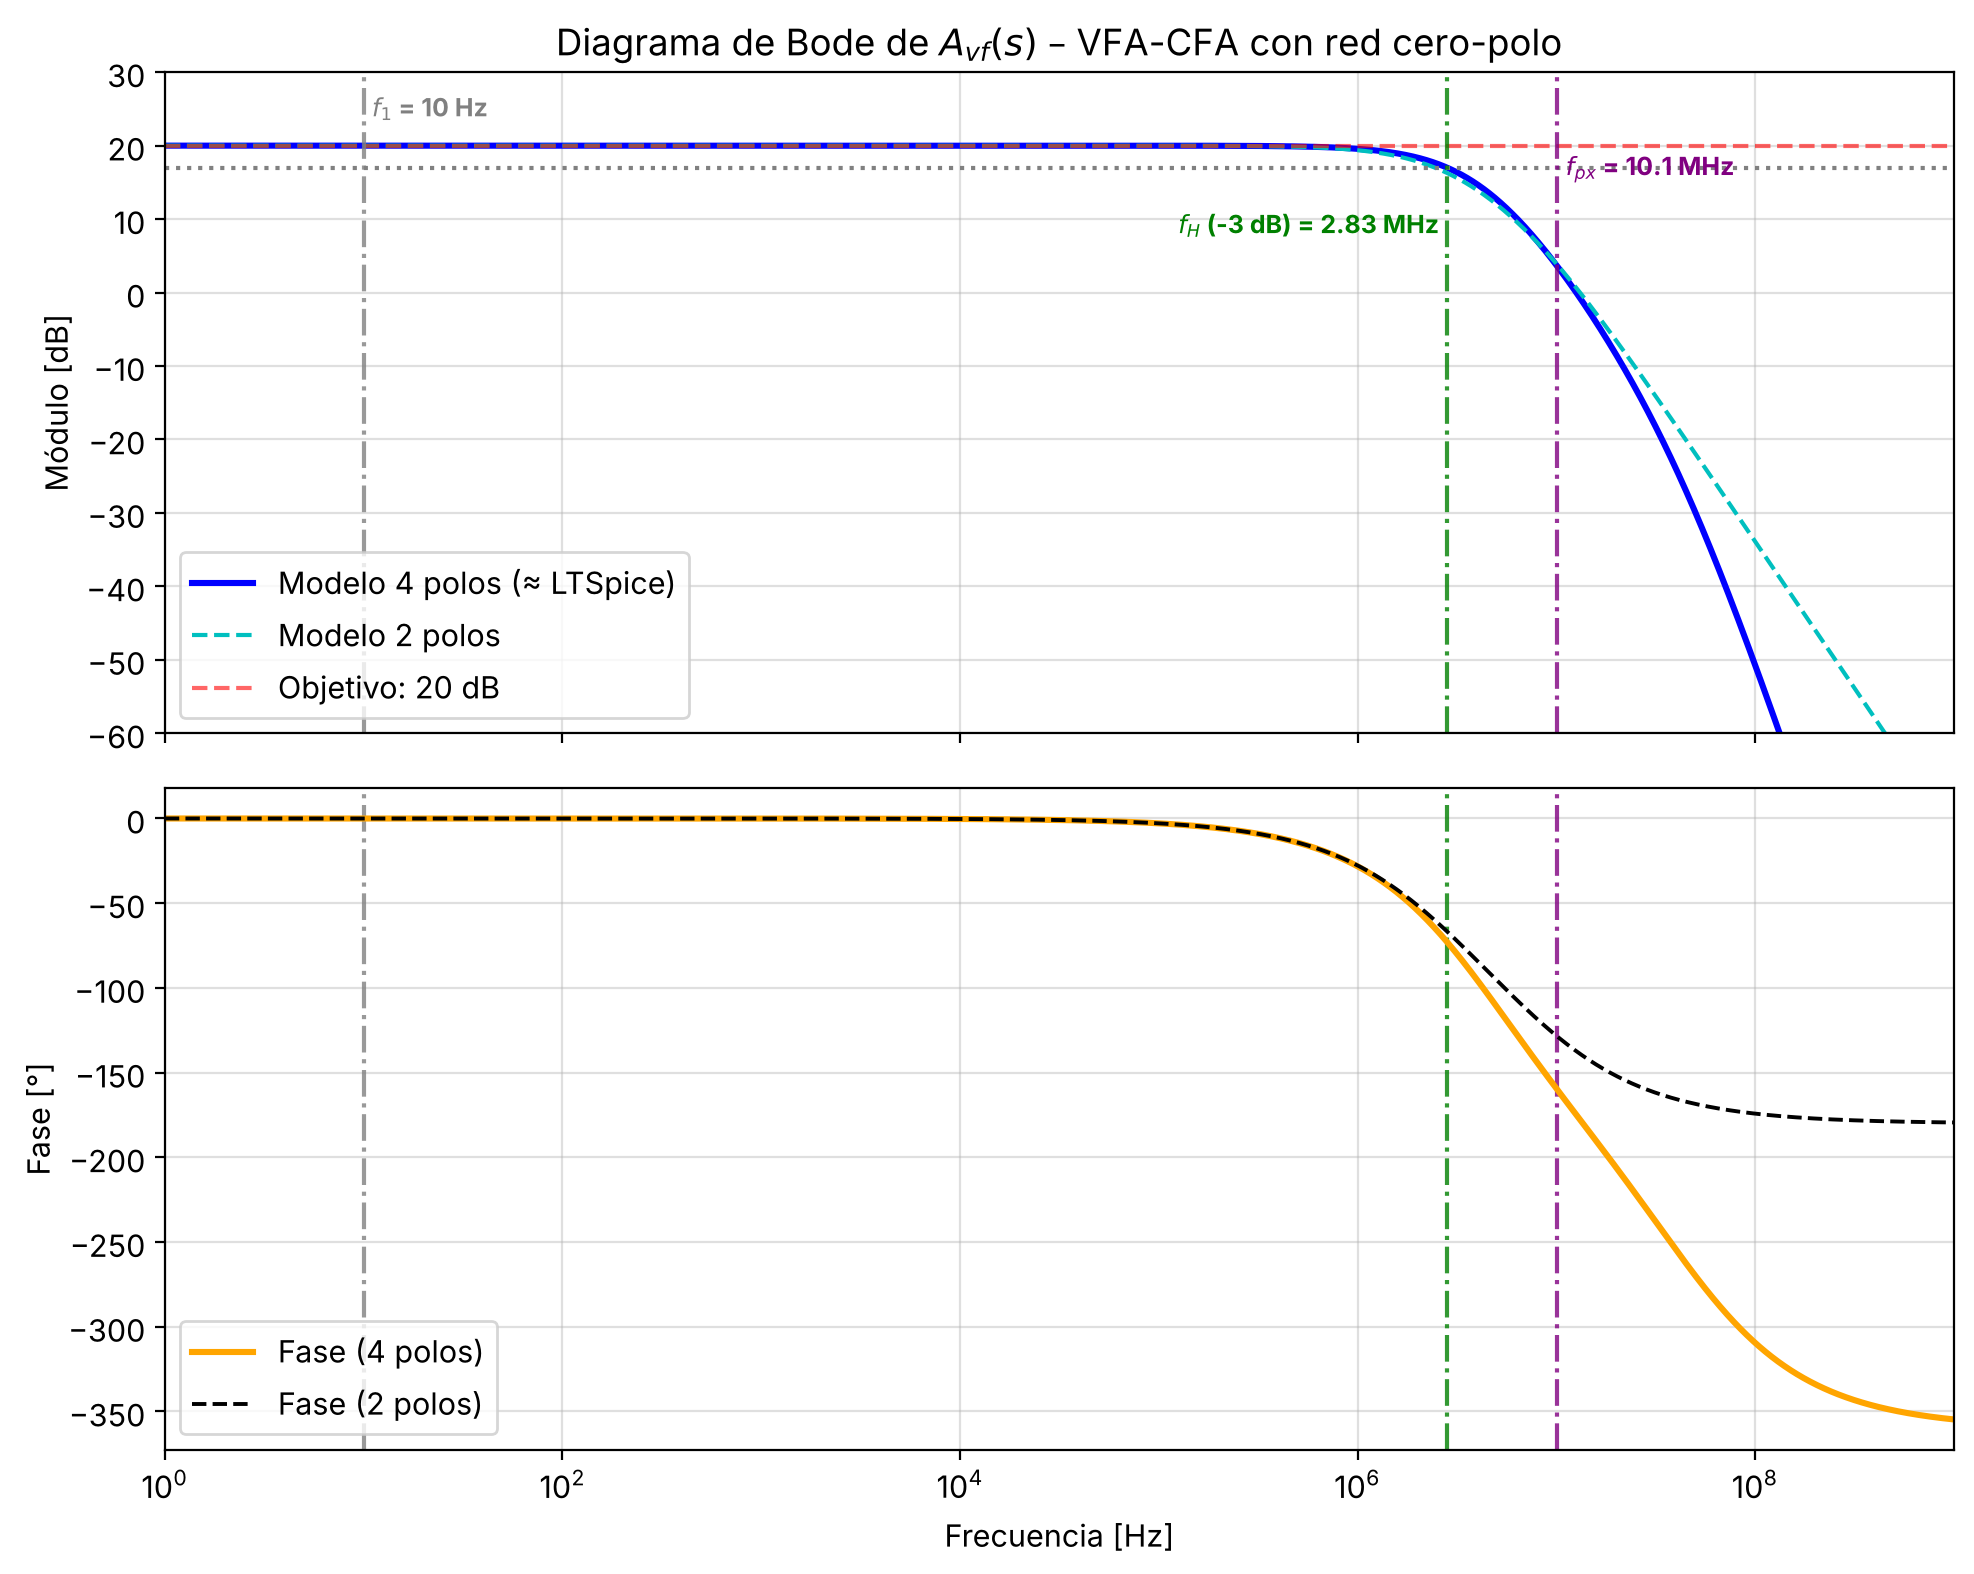

In [7]:
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(10, 8))

ax1.semilogx(f, R4p['magA'], 'b', lw=2.2, label='Modelo 4 polos (≈ LTSpice)')
ax1.semilogx(f, R2p['magA'], 'c--', lw=1.5, label='Modelo 2 polos')
ax1.axhline(Avf_dB, color='r', ls='--', alpha=0.6, label='Objetivo: 20 dB')
ax1.axhline(Avf_dB - 3, color='gray', ls=':')
ax1.set_ylim(-60, 30)
ax1.set_ylabel('Módulo [dB]')
ax1.set_title('Diagrama de Bode de $A_{vf}(s)$ – VFA-CFA con red cero-polo')

def etiq(nombre, fr):
    if fr < 1e3:  return f'{nombre} = {fr:.4g} Hz'
    if fr < 1e6:  return f'{nombre} = {fr/1e3:.4g} kHz'
    return f'{nombre} = {fr/1e6:.3g} MHz'

marcas = [(f1, '$f_1$', 'gray'), (fb, '$f_{px}$', 'purple'), (R4p['BW'], '$f_H$ (-3 dB)', 'green')]
for k, (fr, nombre, color) in enumerate(marcas):
    ax1.axvline(fr, color=color, ls='-.', alpha=0.8)
    ax2.axvline(fr, color=color, ls='-.', alpha=0.8)
    if nombre.startswith('$f_H'):
        ax1.text(fr/1.1, 24 - 8*k, etiq(nombre, fr), color=color, fontsize=9, weight='bold', ha='right')
    else:
        ax1.text(fr*1.1, 24 - 8*k, etiq(nombre, fr), color=color, fontsize=9, weight='bold')
ax1.legend(loc='lower left')

ax2.semilogx(f, R4p['faseA'], color='orange', lw=2.2, label='Fase (4 polos)')
ax2.semilogx(f, R2p['faseA'], 'k--', lw=1.4, label='Fase (2 polos)')
ax2.set_ylabel('Fase [°]'); ax2.set_xlabel('Frecuencia [Hz]')
ax2.set_xlim(1, 1e9); ax2.legend(loc='lower left')

plt.tight_layout()
fig.savefig(f'{CARPETA}/c3_bode_lazo_cerrado.pdf')
plt.show()

### 6.2 Ganancia de lazo $T(s)$

El **margen de fase se define sobre $T(s)$**, no sobre $A_{vf}$. Este gráfico muestra:

* En el módulo: el cruce por 0 dB, que da la frecuencia crítica $f_{Gc}$ (línea verde). La línea roja es el ancho de banda potencial $f_g$ (cruce asintótico).
* En la fase: cuánto falta para −180° en ese punto, que es el **margen de fase** $M_\varphi$. También se marca el margen de ganancia $M_G$.

Debe coincidir con lo que se mide en LTSpice sobre el circuito de ganancia de lazo.

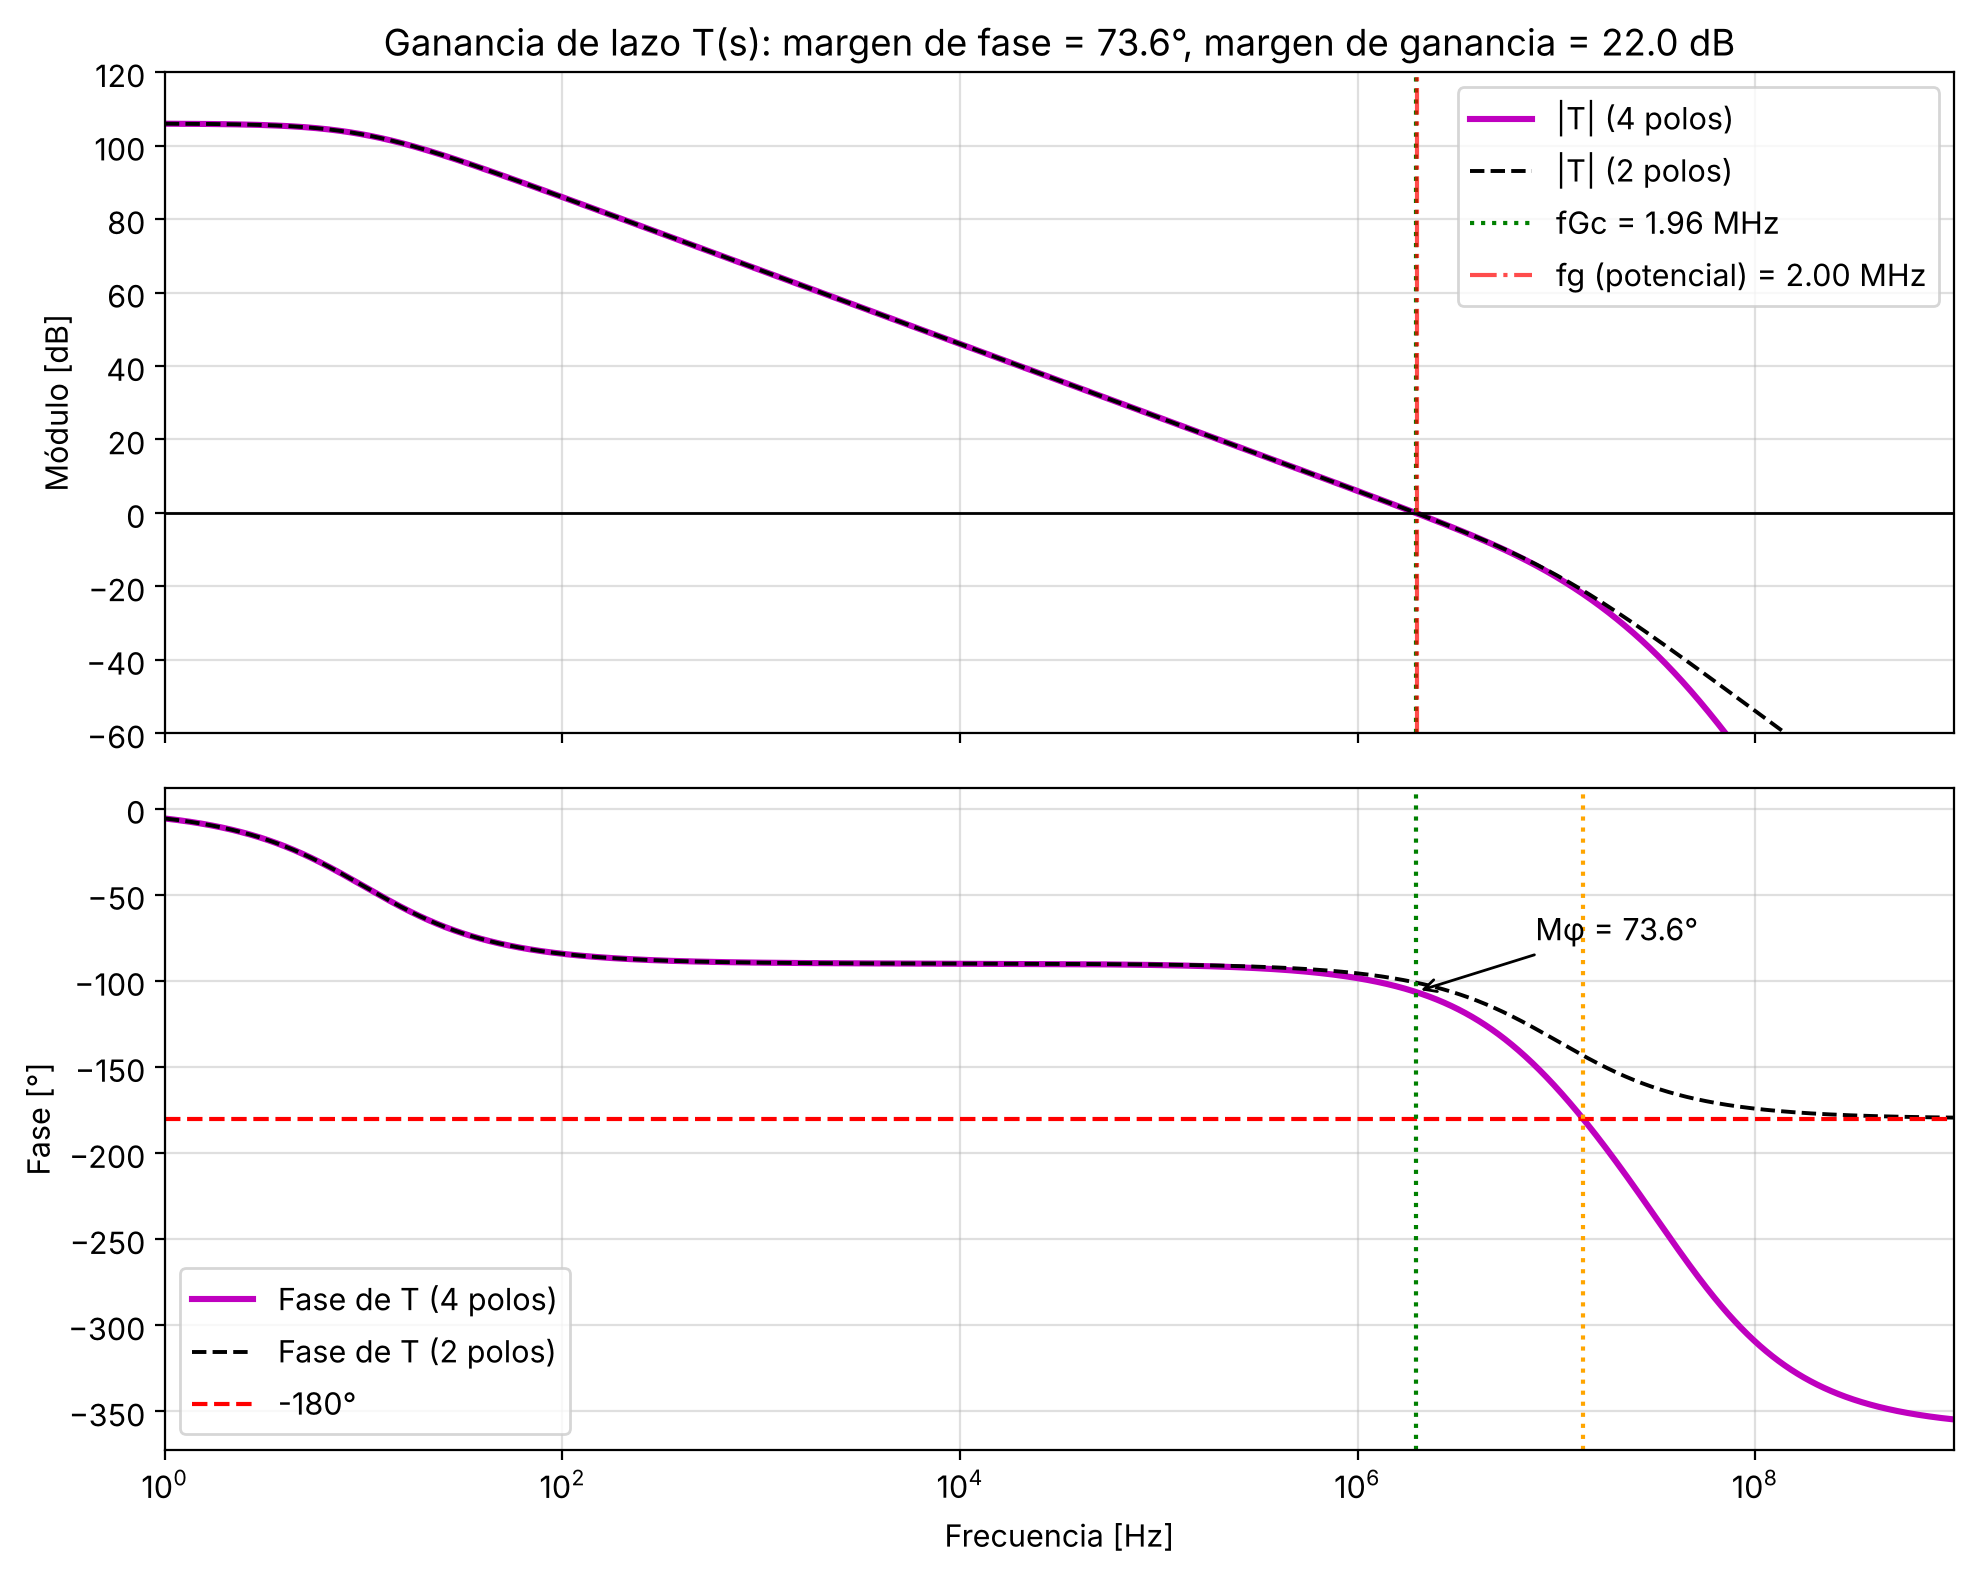

In [8]:
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(10, 8))

ax1.semilogx(f, R4p['magT'], 'm', lw=2.2, label='|T| (4 polos)')
ax1.semilogx(f, R2p['magT'], 'k--', lw=1.4, label='|T| (2 polos)')
ax1.axhline(0, color='k', lw=1)
ax1.axvline(R4p['fGc'], color='g', ls=':', label=f"fGc = {R4p['fGc']/1e6:.2f} MHz")
ax1.axvline(fg_pot, color='r', ls='-.', alpha=0.7, label=f'fg (potencial) = {fg_pot/1e6:.2f} MHz')
ax1.set_ylim(-60, 120); ax1.set_ylabel('Módulo [dB]')
ax1.set_title(f"Ganancia de lazo T(s): margen de fase = {R4p['Mphi']:.1f}°, margen de ganancia = {R4p['MG']:.1f} dB")
ax1.legend()

ax2.semilogx(f, R4p['faseT'], 'm', lw=2.2, label='Fase de T (4 polos)')
ax2.semilogx(f, R2p['faseT'], 'k--', lw=1.4, label='Fase de T (2 polos)')
ax2.axhline(-180, color='r', ls='--', label='-180°')
ax2.axvline(R4p['fGc'], color='g', ls=':')
ax2.axvline(R4p['fpc'], color='orange', ls=':')
ax2.annotate(f"Mφ = {R4p['Mphi']:.1f}°", xy=(R4p['fGc'], R4p['Mphi'] - 180),
             xytext=(R4p['fGc']*4, R4p['Mphi'] - 150), arrowprops=dict(arrowstyle='->'))
ax2.set_ylabel('Fase [°]'); ax2.set_xlabel('Frecuencia [Hz]')
ax2.set_xlim(1, 1e9); ax2.legend(loc='lower left')

plt.tight_layout()
fig.savefig(f'{CARPETA}/c3_bode_ganancia_lazo.pdf')
plt.show()

### 6.3 Cancelación del segundo polo del VFA

Este gráfico muestra cómo actúa la red: el módulo del LM324 ($A_1$, con sus dos polos), el de la red ($A_c$) y el producto $A_1A_c$, que queda con un solo polo (el $f_1$) hasta que aparece el polo de la red una octava después. La fase de $A_1A_c$ sigue en −90° hasta bastante más allá de $f_2$ (menos atraso de fase en la zona del punto crítico), que es lo que mejora el margen de fase.

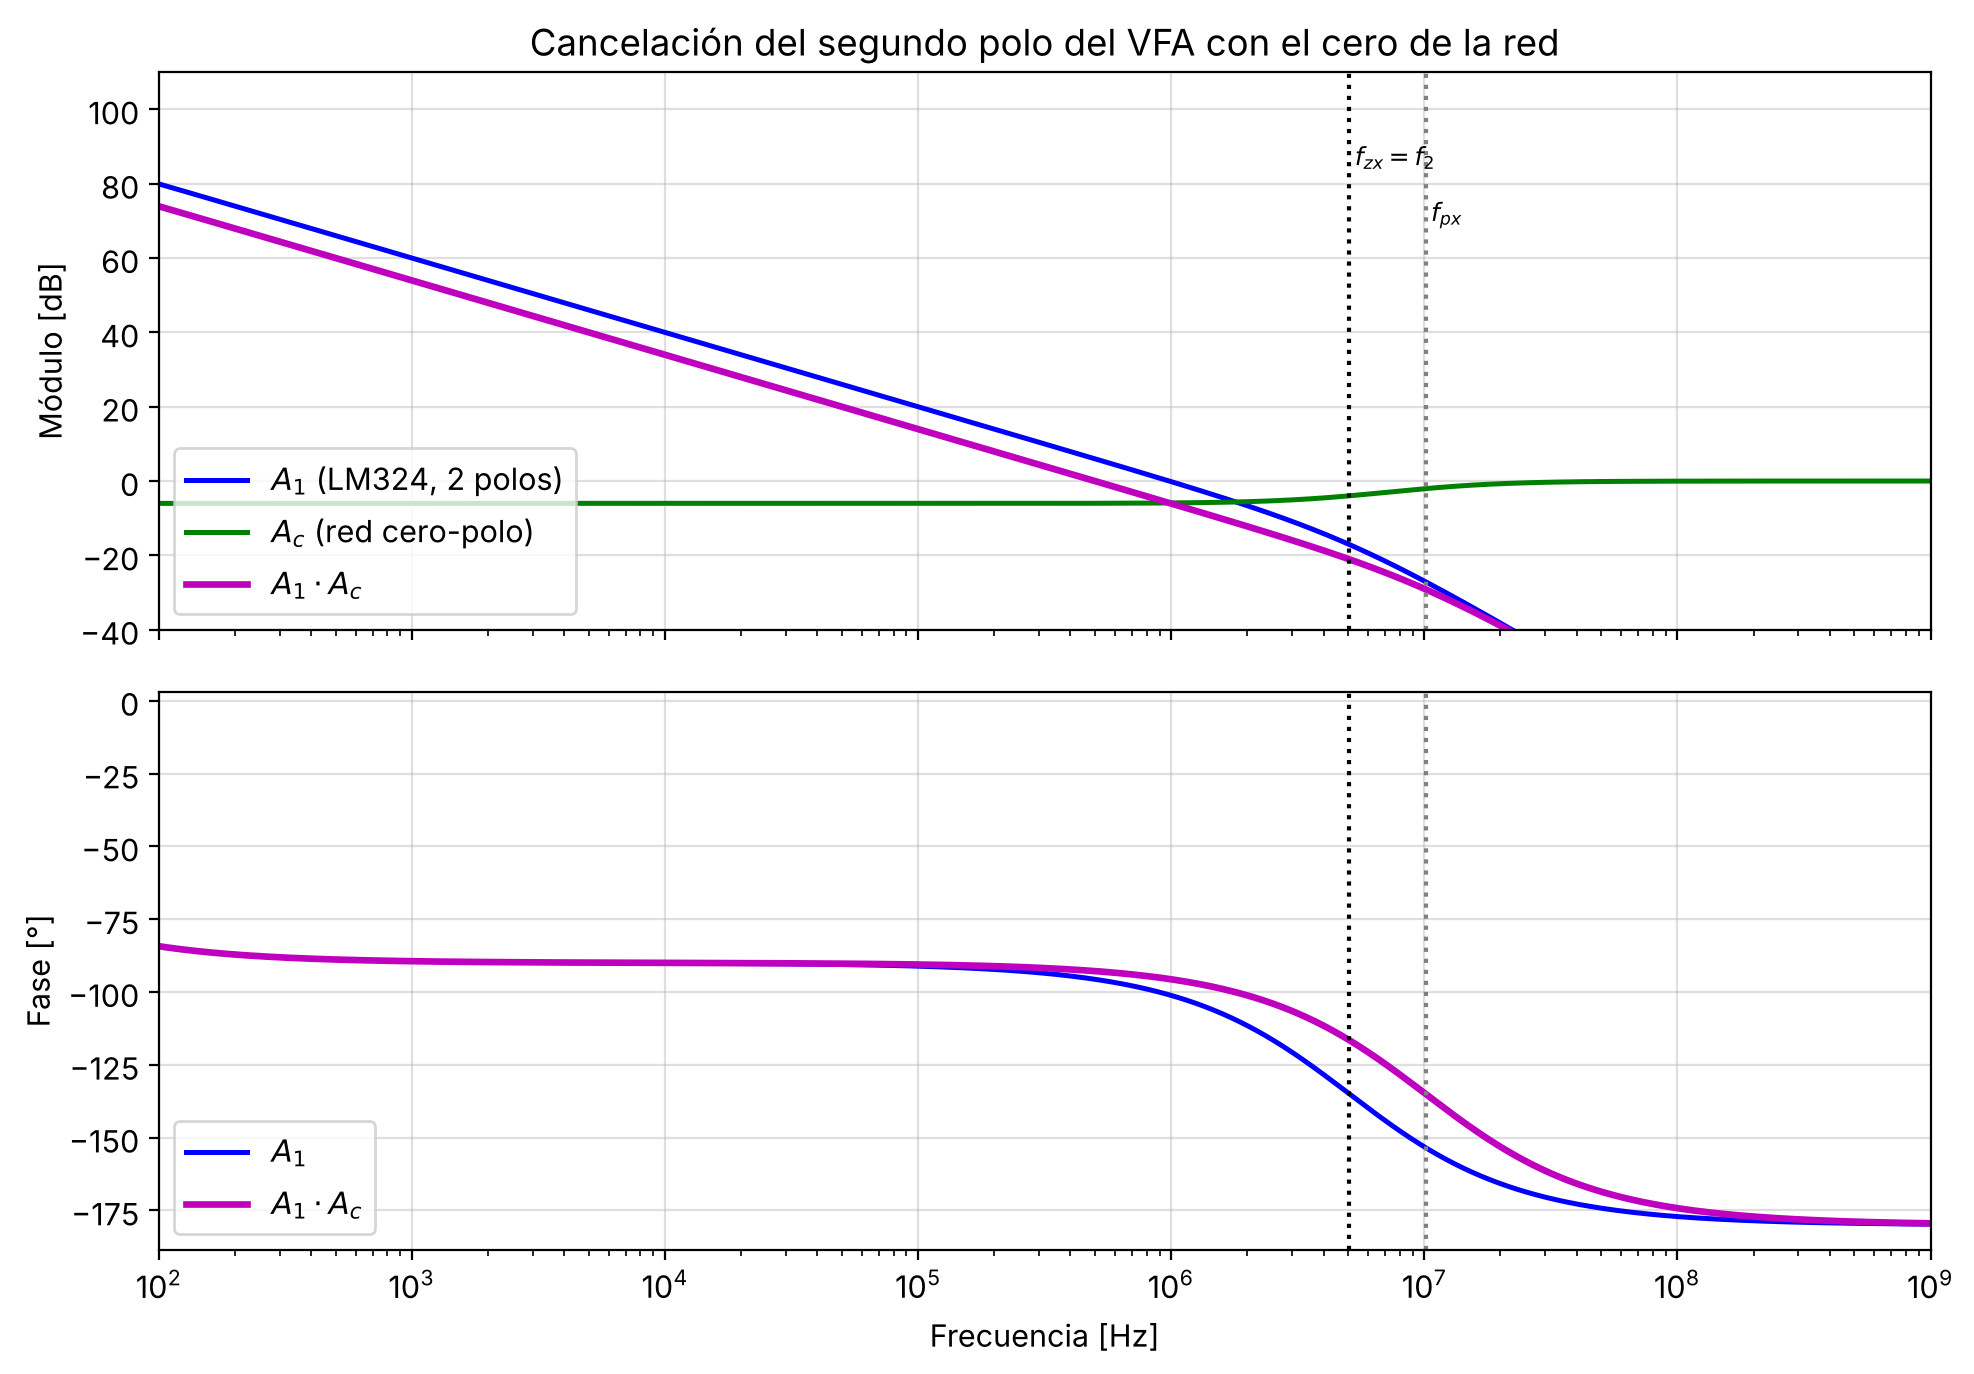

In [9]:
s_ = 1j*2*np.pi*f
A1  = np.polyval(numA, s_)/np.polyval(denA, s_)                                   # LM324 con sus 2 polos
Ac  = N0*(1 + s_/(2*np.pi*fzx))/(1 + s_/(2*np.pi*fpx))                            # red cero-polo
A1c = A1*Ac                                                                        # producto

fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(10, 7))
ax1.semilogx(f, 20*np.log10(abs(A1)),  'b',  lw=1.8, label='$A_1$ (LM324, 2 polos)')
ax1.semilogx(f, 20*np.log10(abs(Ac)),  'g',  lw=1.8, label='$A_c$ (red cero-polo)')
ax1.semilogx(f, 20*np.log10(abs(A1c)), 'm',  lw=2.4, label=r'$A_1 \cdot A_c$')
ax1.axvline(fzx, color='k', ls=':'); ax1.axvline(fpx, color='gray', ls=':')
ax1.text(fzx*1.05, 85, '$f_{zx}=f_2$', fontsize=9); ax1.text(fpx*1.05, 70, '$f_{px}$', fontsize=9)
ax1.set_ylim(-40, 110); ax1.set_xlim(1e2, 1e9); ax1.set_ylabel('Módulo [dB]'); ax1.legend(loc='lower left')
ax1.set_title('Cancelación del segundo polo del VFA con el cero de la red')

ax2.semilogx(f, np.degrees(np.unwrap(np.angle(A1))),  'b', lw=1.8, label='$A_1$')
ax2.semilogx(f, np.degrees(np.unwrap(np.angle(A1c))), 'm', lw=2.4, label=r'$A_1 \cdot A_c$')
ax2.axvline(fzx, color='k', ls=':'); ax2.axvline(fpx, color='gray', ls=':')
ax2.set_ylabel('Fase [°]'); ax2.set_xlabel('Frecuencia [Hz]'); ax2.legend(loc='lower left')
plt.tight_layout()
fig.savefig(f'{CARPETA}/c3_cancelacion_polo.pdf')
plt.show()

### Sensibilidad al valor de $r_i$

Como el fabricante no publica $r_i$ (el apunte menciona 20 Ω y 30 Ω), se repite el modelo de 4 polos con distintos valores para ver cuánto cambian los resultados. **Si la diferencia es chica, el supuesto no es crítico.**

In [10]:
filas_ri = []
for ri_v in [1e-3, 10, 20, 30, 50]:
    n_, d_ = armar_4p(ri_v)
    T_, A_, dc_ = lazo(n_, d_)
    r_ = medir(T_, A_, dc_)
    filas_ri.append([f'{ri_v:g}', f"{(R2 + ri_v*G0):.0f}", f"{r_['fGc']/1e6:.3f}", f"{r_['Mphi']:.1f}",
                     f"{r_['MG']:.1f}", f"{r_['BW']/1e6:.3f}", f"{r_['pico']:.2f}"])
tabla_ri = pd.DataFrame(filas_ri, columns=['ri [Ω]', 'Reff [Ω]', 'fGc [MHz]', 'Margen de fase [°]',
                                           'Margen de ganancia [dB]', 'BW -3 dB [MHz]', 'Pico [dB]']).set_index('ri [Ω]')
print('TABLA – Sensibilidad al valor de ri (modelo de 4 polos)')
display(tabla_ri)

TABLA – Sensibilidad al valor de ri (modelo de 4 polos)


,Reff [Ω],fGc [MHz],Margen de fase [°],Margen de ganancia [dB],BW -3 dB [MHz],Pico [dB]
ri [Ω],,,,,,
0.001,820,1.963,76.2,26.3,2.637,0.00
10,1220,1.961,74.9,23.7,2.731,0.00
20,1620,1.958,73.6,22.0,2.826,0.00
30,2020,1.954,72.3,20.9,2.920,0.00
50,2820,1.943,69.7,19.3,3.093,0.00


## 7. Comparación con el Caso 2 (constatar la mejora)

Se miden las mismas magnitudes en el modelo de 4 polos del **Caso 2** (sin red, $G_0^{(\text{Caso 2})}$) y se las pone al lado de las del Caso 3. Qué se espera ver:

* Mismo $T_0$ y mismo $f_g$ (la red atenúa a la mitad y el CFA compensa).
* **Mayor margen de fase** en el Caso 3, porque el cero cancela el atraso de fase del 2° polo del VFA y el polo de la red está más lejos.
* Ancho de banda real parecido o algo menor (la respuesta queda más amortiguada).

TABLA – Caso 2 vs. Caso 3 (modelo de 4 polos)


,Caso 2 (sin red),Caso 3 (con red)
Magnitud,,
Frecuencia crítica fGc [MHz],1.873,1.958
Margen de fase [°],65.74,73.58
Margen de ganancia [dB],23.2,22.0
Ancho de banda real (-3 dB) [MHz],3.039,2.826
Frecuencia de los polos fp [MHz],3.165,4.391
Factor de calidad Qp,0.681,0.503
Pico del módulo [dB],0.00,0.00


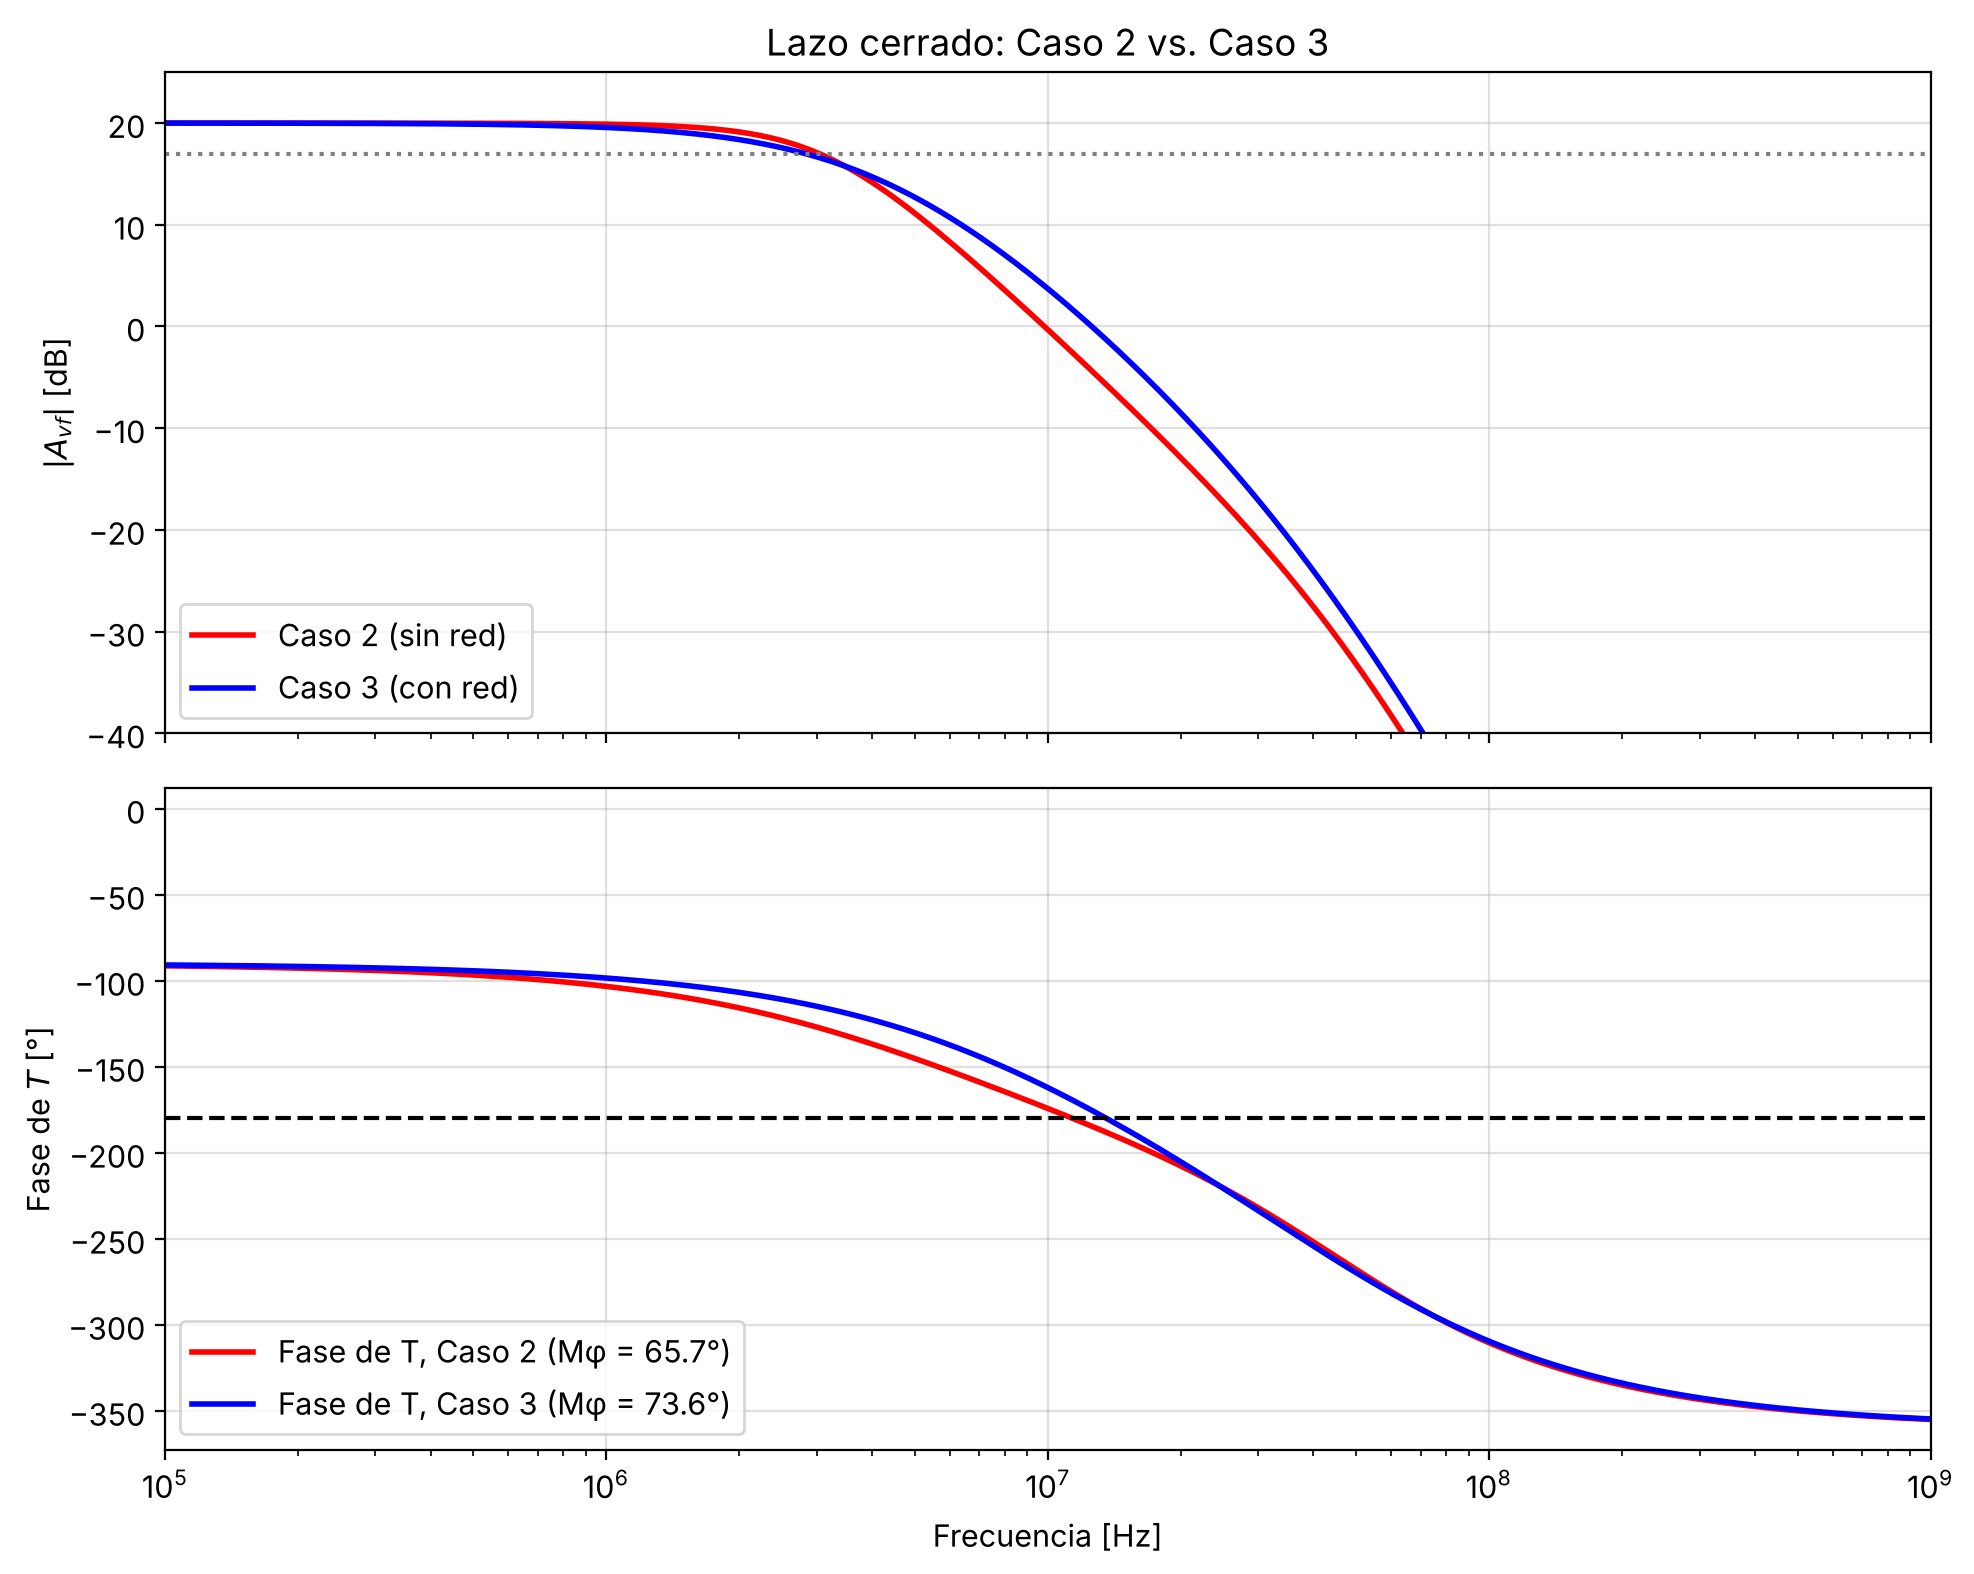

In [11]:
R4c2 = medir(T_4c2, Acl_4c2, den_cl_4c2)

tabla_comp = pd.DataFrame({
    'Magnitud': ['Frecuencia crítica fGc [MHz]', 'Margen de fase [°]', 'Margen de ganancia [dB]',
                 'Ancho de banda real (-3 dB) [MHz]', 'Frecuencia de los polos fp [MHz]', 'Factor de calidad Qp', 'Pico del módulo [dB]'],
    'Caso 2 (sin red)':   [f"{R4c2['fGc']/1e6:.3f}", f"{R4c2['Mphi']:.2f}", f"{R4c2['MG']:.1f}", f"{R4c2['BW']/1e6:.3f}",
                            f"{R4c2['fp']/1e6:.3f}", f"{R4c2['Q']:.3f}", f"{R4c2['pico']:.2f}"],
    'Caso 3 (con red)':   [f"{R4p['fGc']/1e6:.3f}", f"{R4p['Mphi']:.2f}", f"{R4p['MG']:.1f}", f"{R4p['BW']/1e6:.3f}",
                            f"{R4p['fp']/1e6:.3f}", f"{R4p['Q']:.3f}", f"{R4p['pico']:.2f}"],
}).set_index('Magnitud')
print('TABLA – Caso 2 vs. Caso 3 (modelo de 4 polos)')
display(tabla_comp)

fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(10, 8))
ax1.semilogx(f, R4c2['magA'], 'r', lw=2, label='Caso 2 (sin red)')
ax1.semilogx(f, R4p['magA'],  'b', lw=2, label='Caso 3 (con red)')
ax1.axhline(Avf_dB - 3, color='gray', ls=':')
ax1.set_ylim(-40, 25); ax1.set_xlim(1e5, 1e9); ax1.set_ylabel('$|A_{vf}|$ [dB]'); ax1.legend(loc='lower left')
ax1.set_title('Lazo cerrado: Caso 2 vs. Caso 3')
ax2.semilogx(f, R4c2['faseT'], 'r', lw=2, label=f"Fase de T, Caso 2 (Mφ = {R4c2['Mphi']:.1f}°)")
ax2.semilogx(f, R4p['faseT'],  'b', lw=2, label=f"Fase de T, Caso 3 (Mφ = {R4p['Mphi']:.1f}°)")
ax2.axhline(-180, color='k', ls='--')
ax2.set_ylabel('Fase de $T$ [°]'); ax2.set_xlabel('Frecuencia [Hz]'); ax2.legend(loc='lower left')
plt.tight_layout()
fig.savefig(f'{CARPETA}/c3_comparacion_caso2.pdf')
plt.show()

## 8. Mediciones de LTSpice (consigna c.3)

**Esta es la única celda que hay que editar a mano.** Cargá acá lo que midas en LTSpice. Mientras estén en `None`, las tablas muestran `--`.

| Variable | Qué es | Dónde se mide en LTSpice |
|---|---|---|
| `fg_sim` | Frecuencia donde la ganancia de lazo cruza 0 dB | Circuito de ganancia de lazo |
| `Mphi_sim` | Margen de fase | Idem (`Phase Margin`) |
| `MG_sim`, `fpc_sim` | Margen de ganancia y frecuencia donde la fase de $T$ llega a −180° | Idem |
| `BW_sim` | Ancho de banda a −3 dB | Circuito a lazo cerrado, cursor a 17 dB |
| `Vpico_sim`, `Vest_sim` | Tensión pico y de régimen de la salida ante el escalón | Simulación temporal |
| `Vin_escalon` | Amplitud del escalón de entrada | Fuente de entrada |

**Sugerencia:** usá un escalón **chico** (p. ej. 0,1 V). Con la red el sobrepico es muy pequeño, así que conviene ampliar la zona del pico en el cursor. Si no se ve ningún sobrepico, dejá `Vpico_sim = Vest_sim`.

In [12]:
# ====== EDITAR ACÁ con las mediciones de LTSpice (dejar None si todavía no se midió) ======
fg_sim      = 1957000.0    # [Hz]  cruce de 0 dB de la ganancia de lazo
Mphi_sim    = 73.617    # [°]   margen de fase medido
MG_sim      = None    # [dB]  margen de ganancia medido
fpc_sim     = None    # [Hz]  frecuencia donde la fase de T llega a -180°
BW_sim      = 2.823e6    # [Hz]  ancho de banda a -3 dB (lazo cerrado)
Vpico_sim   = 1.0    # [V]   pico de la respuesta al escalón
Vest_sim    = 1.0    # [V]   valor de régimen
Vin_escalon = 0.1     # [V]   amplitud del escalón de entrada usado en LTSpice
# ===========================================================================================
print('Mediciones cargadas:', {k: v for k, v in dict(fg=fg_sim, Mphi=Mphi_sim, MG=MG_sim, BW=BW_sim, Vpico=Vpico_sim).items()})

Mediciones cargadas: {'fg': 1957000.0, 'Mphi': 73.617, 'MG': None, 'BW': 2823000.0, 'Vpico': 1.0}


## 9. Respuesta al escalón y margen de fase estimado (consigna c.4)

**Idea:** un sistema subamortiguado supera su valor final al responder a un escalón. El tamaño de ese **sobrepico** indica el amortiguamiento, y éste el margen de fase:

1. Sobrepico porcentual: $\%OS=\dfrac{V_{pico}-V_{est}}{V_{est}}\cdot100$
2. Amortiguamiento: $\zeta=\dfrac{-\ln(\%OS/100)}{\sqrt{\pi^2+\ln^2(\%OS/100)}}$
3. Margen de fase: $M_\varphi=\arctan\!\left(\dfrac{2\zeta}{\sqrt{\sqrt{1+4\zeta^4}-2\zeta^2}}\right)$

La celda aplica esas ecuaciones al modelo de 2 polos, al de 4 polos (con `scipy`) y a la **medición de LTSpice** (si está cargada).

> **Si no hay sobrepico** (%OS < 0,05 %) no se puede estimar $\zeta$ con esta fórmula: significa $\zeta\gtrsim0{,}9$, es decir un margen de fase **superior a unos 73°**. La celda lo indica así.
> Estas relaciones son exactas solo para 2° orden; con 4 polos son una estimación.

TABLA 4 – Respuesta al escalón y margen de fase estimado


,Modelo 2 polos,Modelo 4 polos,LTSpice (medido)
Magnitud,,,
Vpico [V],1.0000,1.0000,1.0000
Vestacionario [V],1.0000,1.0000,1.0000
Sobrepico %OS,sin sobrepico,sin sobrepico,sin sobrepico
Amortiguamiento ζ,--,--,--
Margen de fase estimado [°],--,--,--


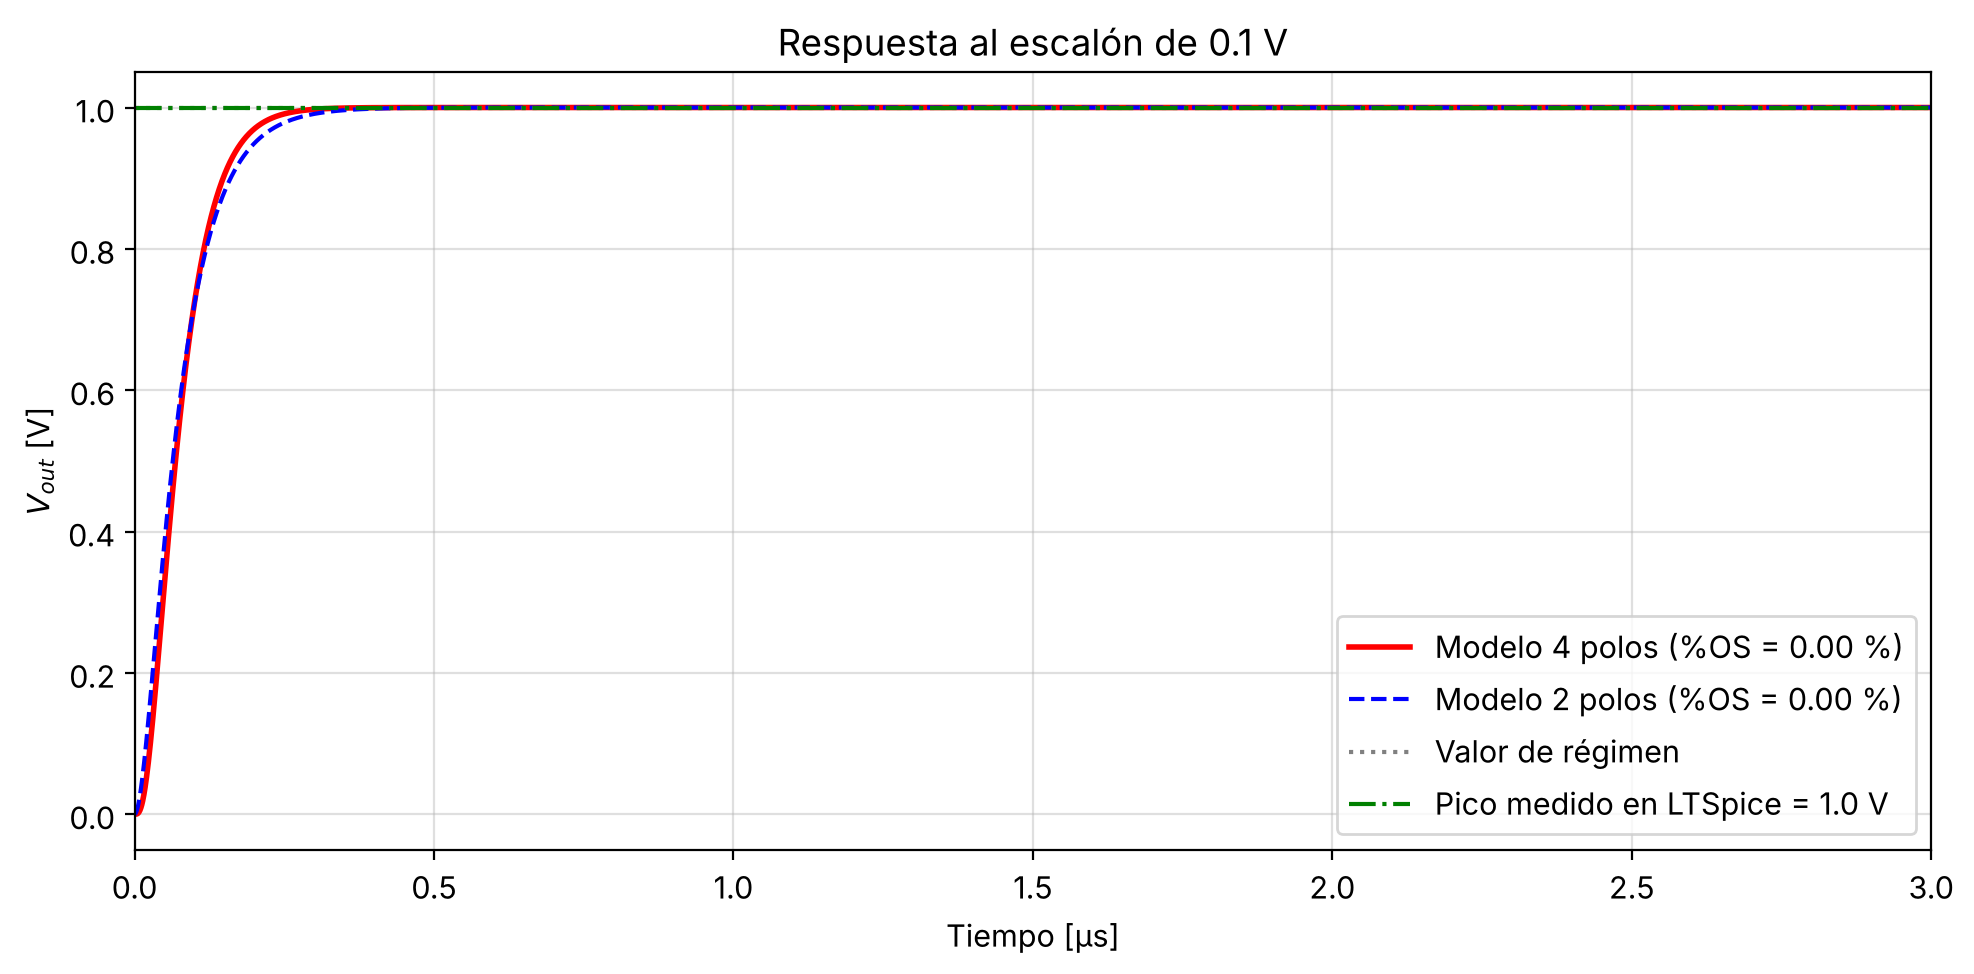

In [13]:
OS_MIN = 0.05                                        # [%] por debajo de esto se considera "sin sobrepico"

def escalon(den_cl, num_G, t_max=6e-6):
    t = np.linspace(0, t_max, 12001)
    t, y = signal.step(signal.TransferFunction(num_G*Vin_escalon, den_cl), T=t)
    return t, y

def sobrepico(Vpico, Vest):
    if Vpico is None or Vest is None:
        return None
    return max((Vpico - Vest)/Vest*100, 0.0)

def zeta_de_OS(OS):                                  # Ecuación del amortiguamiento
    if OS is None or OS < OS_MIN:
        return np.nan
    x = np.log(OS/100)
    return -x/np.sqrt(np.pi**2 + x**2)

def MF_de_zeta(z):                                   # Ecuación del margen de fase
    return np.degrees(np.arctan(2*z/np.sqrt(np.sqrt(1 + 4*z**4) - 2*z**2)))

def fmt(v, dec=2):
    return '--' if (v is None or (isinstance(v, float) and np.isnan(v))) else f'{v:.{dec}f}'

t2, y2 = escalon(den_cl_2p, num_2p)
t4, y4 = escalon(den_cl_4p, num_4p)

OS_2p  = sobrepico(y2.max(), y2[-1])
OS_4p  = sobrepico(y4.max(), y4[-1])
OS_sim = sobrepico(Vpico_sim, Vest_sim)

z_2p, z_4p, z_sim = zeta_de_OS(OS_2p), zeta_de_OS(OS_4p), zeta_de_OS(OS_sim)
MF_2p, MF_4p = MF_de_zeta(z_2p), MF_de_zeta(z_4p)
MF_sim = MF_de_zeta(z_sim) if not np.isnan(z_sim) else np.nan

def txt_OS(OS):
    if OS is None: return '--'
    return 'sin sobrepico' if OS < OS_MIN else f'{OS:.2f}'

tabla_escalon = pd.DataFrame({
    'Magnitud': ['Vpico [V]', 'Vestacionario [V]', 'Sobrepico %OS', 'Amortiguamiento ζ', 'Margen de fase estimado [°]'],
    'Modelo 2 polos': [f'{y2.max():.4f}', f'{y2[-1]:.4f}', txt_OS(OS_2p), fmt(z_2p, 4), fmt(MF_2p)],
    'Modelo 4 polos': [f'{y4.max():.4f}', f'{y4[-1]:.4f}', txt_OS(OS_4p), fmt(z_4p, 4), fmt(MF_4p)],
    'LTSpice (medido)': [fmt(Vpico_sim, 4), fmt(Vest_sim, 4), txt_OS(OS_sim), fmt(z_sim, 4), fmt(MF_sim)],
}).set_index('Magnitud')

print('TABLA 4 – Respuesta al escalón y margen de fase estimado')
display(tabla_escalon)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(t4*1e6, y4, 'r', lw=2, label=f'Modelo 4 polos (%OS = {fmt(OS_4p)} %)')
ax.plot(t2*1e6, y2, 'b--', lw=1.5, label=f'Modelo 2 polos (%OS = {fmt(OS_2p)} %)')
ax.axhline(y4[-1], color='gray', ls=':', label='Valor de régimen')
if Vpico_sim is not None:
    ax.axhline(Vpico_sim, color='green', ls='-.', label=f'Pico medido en LTSpice = {Vpico_sim} V')
ax.set_xlim(0, 3); ax.set_xlabel('Tiempo [µs]'); ax.set_ylabel('$V_{out}$ [V]')
ax.set_title(f'Respuesta al escalón de {Vin_escalon:g} V'); ax.legend(loc='lower right')
plt.tight_layout()
fig.savefig(f'{CARPETA}/c3_escalon_teorico.pdf')
plt.show()

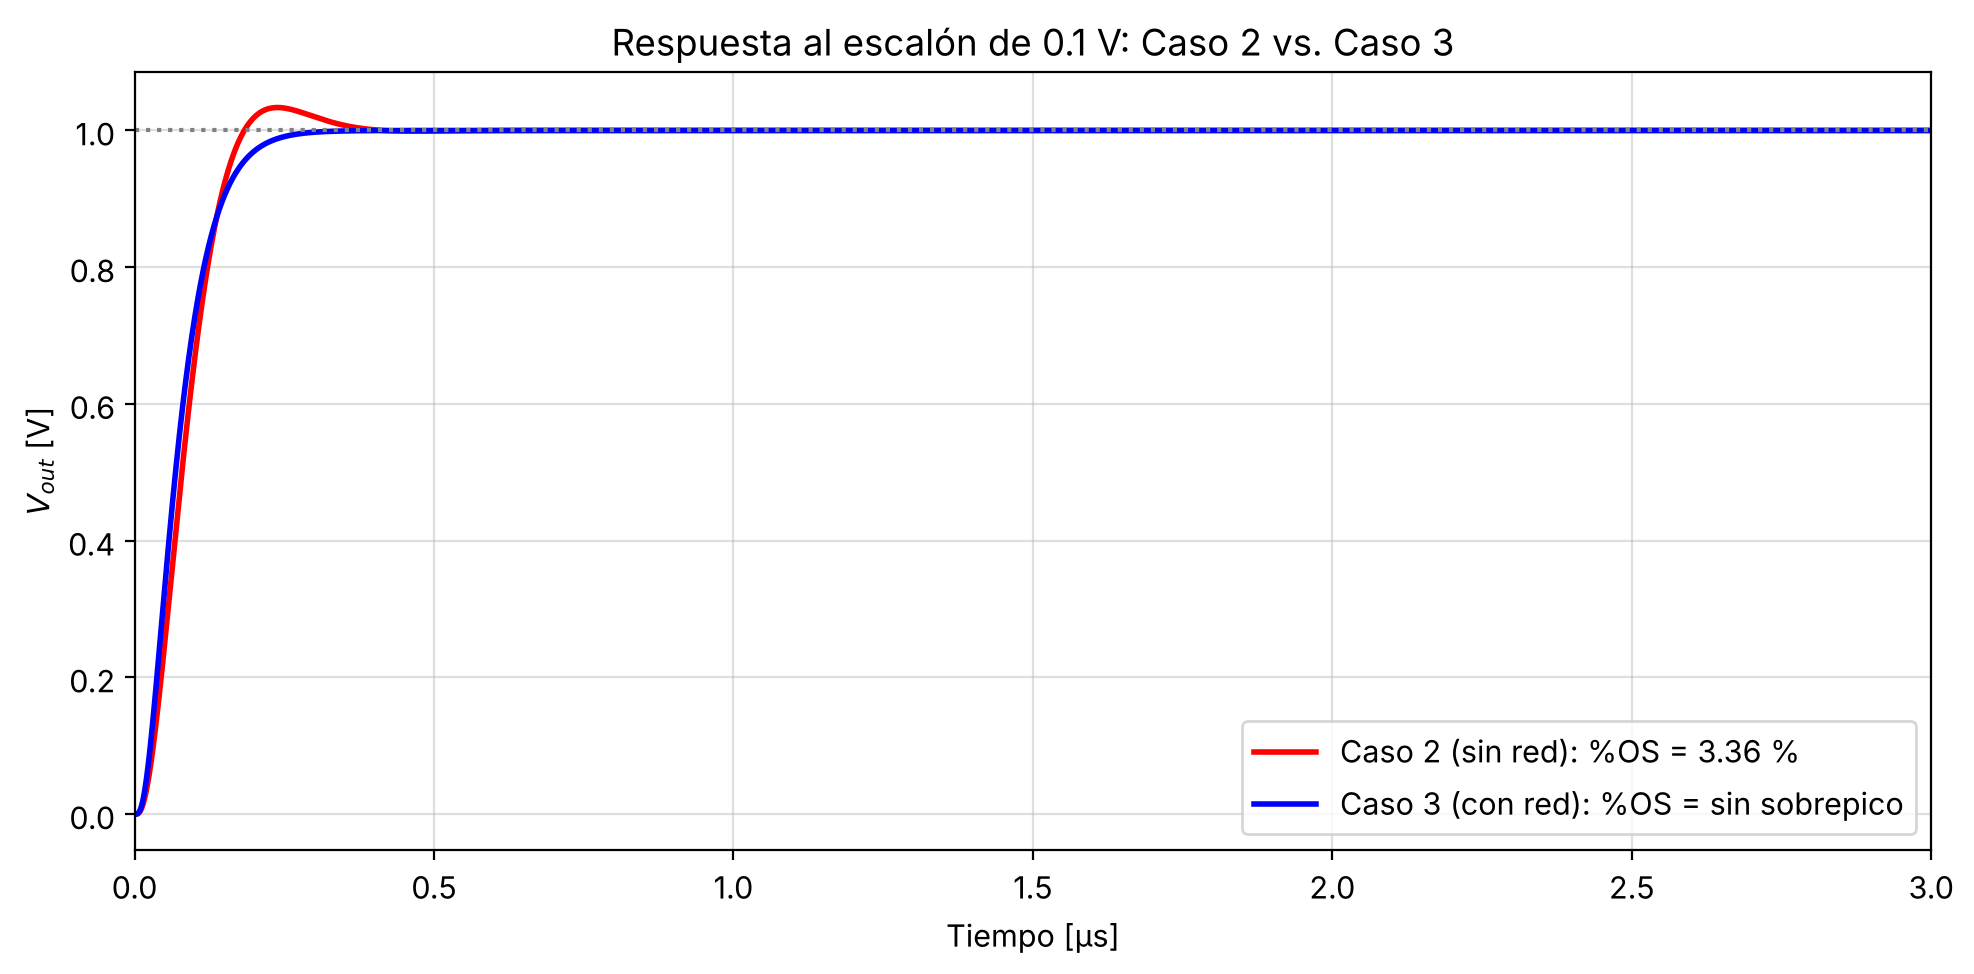

Caso 2: %OS = 3.36 % -> ζ = 0.7339 -> Mφ estimado = 66.88°
Caso 3: %OS = sin sobrepico -> el margen de fase estimado por el escalón es > 73° (sin sobrepico)


In [14]:
# Comparación con el Caso 2 (modelo de 4 polos) en el escalón
t4c, y4c = escalon(den_cl_4c2, num_4p_c2)
OS_c2 = sobrepico(y4c.max(), y4c[-1])
z_c2 = zeta_de_OS(OS_c2); MF_c2 = MF_de_zeta(z_c2)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(t4c*1e6, y4c, 'r', lw=2, label=f'Caso 2 (sin red): %OS = {fmt(OS_c2)} %')
ax.plot(t4*1e6, y4, 'b', lw=2, label=f'Caso 3 (con red): %OS = {txt_OS(OS_4p)}')
ax.axhline(y4[-1], color='gray', ls=':')
ax.set_xlim(0, 3); ax.set_xlabel('Tiempo [µs]'); ax.set_ylabel('$V_{out}$ [V]')
ax.set_title(f'Respuesta al escalón de {Vin_escalon:g} V: Caso 2 vs. Caso 3'); ax.legend(loc='lower right')
plt.tight_layout()
fig.savefig(f'{CARPETA}/c3_escalon_comparacion.pdf')
plt.show()
print(f'Caso 2: %OS = {fmt(OS_c2)} % -> ζ = {fmt(z_c2,4)} -> Mφ estimado = {fmt(MF_c2)}°')
print(f'Caso 3: %OS = {txt_OS(OS_4p)} -> el margen de fase estimado por el escalón es > 73° (sin sobrepico)')

## 10. Tabla final: teoría vs. simulación

Se juntan todos los resultados en una sola tabla, uno por fila. Para cada magnitud se muestran el valor **analítico** (fórmulas cerradas, sección 3), el del **modelo de 4 polos** (sección 5) y el medido en **LTSpice** (sección 8). Los errores se calculan como
$$\varepsilon=\frac{\text{teórico}-\text{simulado}}{\text{simulado}}\cdot100$$
(igual que en el informe). Si todavía no se cargó una medición, la celda muestra `--`.

Esta es la tabla que va en el informe. Se guarda también como `.csv` y `.tex`.

In [15]:
def error(teo, sim):
    if sim is None or teo is None or sim == 0 or (isinstance(teo, float) and np.isnan(teo)) or (isinstance(sim, float) and np.isnan(sim)):
        return '--'
    return f'{(teo - sim)/sim*100:+.1f}'

def texto(v, esc, dec):
    return '--' if (v is None or (isinstance(v, float) and np.isnan(v))) else f'{v*esc:.{dec}f}'

OS_txt = lambda v: texto(v, 1, 2)

# (nombre, analítico, modelo 4 polos, LTSpice, factor de escala, decimales)
filas = [
    ('Ancho de banda potencial fg [MHz]',            fg_pot,   None,         None,      1e-6, 3),
    ('Cruce de T, fGc (exacto) [MHz]',               fGc_ex,   R4p['fGc'],   fg_sim,    1e-6, 3),
    ('Margen de fase del lazo [°]',                  Mphi_an,  R4p['Mphi'],  Mphi_sim,  1,    2),
    ('Frecuencia de los polos fp [MHz]',             fp,       R4p['fp'],    None,      1e-6, 3),
    ('Ancho de banda real fH (-3 dB) [MHz]',         fH_an,    R4p['BW'],    BW_sim,    1e-6, 3),
    ('Sobrepico %OS [%]',                            OS_2p,    OS_4p,        OS_sim,    1,    2),
    ('Margen de fase desde el escalón [°]',          MF_2p,    MF_4p,        MF_sim,    1,    2),
]

tabla_final = pd.DataFrame({
    'Magnitud':        [r[0] for r in filas],
    'Analítico':       [texto(r[1], r[4], r[5]) for r in filas],
    'Modelo 4 polos':  [texto(r[2], r[4], r[5]) for r in filas],
    'LTSpice':         [texto(r[3], r[4], r[5]) for r in filas],
    'Error anal. [%]': [error(r[1], r[3]) for r in filas],
    'Error 4 polos [%]': [error(r[2], r[3]) for r in filas],
}).set_index('Magnitud')

print('TABLA FINAL – Caso 3 (VFA-CFA con red cero-polo): teoría vs. simulación')
display(tabla_final)
print(f'\nMargen de ganancia (modelo de 4 polos): {R4p["MG"]:.1f} dB en {R4p["fpc"]/1e6:.2f} MHz')

TABLA FINAL – Caso 3 (VFA-CFA con red cero-polo): teoría vs. simulación


,Analítico,Modelo 4 polos,LTSpice,Error anal. [%],Error 4 polos [%]
Magnitud,,,,,
Ancho de banda potencial fg [MHz],2.000,--,--,--,--
"Cruce de T, fGc (exacto) [MHz]",1.963,1.958,1.957,+0.3,+0.0
Margen de fase del lazo [°],79.02,73.58,73.62,+7.3,-0.0
Frecuencia de los polos fp [MHz],4.499,4.391,--,--,--
Ancho de banda real fH (-3 dB) [MHz],2.455,2.826,2.823,-13.0,+0.1
Sobrepico %OS [%],0.00,0.00,0.00,--,--
Margen de fase desde el escalón [°],--,--,--,--,--



Margen de ganancia (modelo de 4 polos): 22.0 dB en 13.59 MHz


## 11. Guardar las tablas para el informe

La celda guarda las tablas en `salidas_caso3`: `.csv` (para abrir en Excel) y `.tex` (para incluir en LaTeX; requiere `booktabs`). Las figuras ya se guardaron como PDF en las secciones anteriores.

Si estás en **Google Colab**, además descarga todo en un `.zip`. Fuera de Colab no hace nada más (el aviso de "google.colab" en VS Code se puede ignorar).

In [16]:
def guardar(df, nombre, titulo, etiqueta):
    df.to_csv(f'{CARPETA}/{nombre}.csv', encoding='utf-8-sig')
    cols = ' & '.join(['Magnitud'] + list(df.columns)) + r' \\'
    lineas = [r'\begin{table}[H]', r'\centering', r'\begin{tabular}{l' + 'c'*len(df.columns) + '}', r'\toprule', cols, r'\midrule']
    for idx, fila in df.iterrows():
        lineas.append(' & '.join([str(idx)] + [str(v) for v in fila.values]).replace('%', r'\%').replace('°', r'$^\circ$').replace('_', r'\_') + r' \\')
    lineas += [r'\bottomrule', r'\end{tabular}', rf'\caption{{{titulo}}}', rf'\label{{{etiqueta}}}', r'\end{table}']
    open(f'{CARPETA}/{nombre}.tex', 'w', encoding='utf-8').write('\n'.join(lineas))

guardar(tabla_diseno,     'tabla_diseno',     'Parámetros de diseño (VFA-CFA con red cero-polo).', 'tab:diseno_c3')
guardar(tabla_analitica,  'tabla_analitica',  'Resultados analíticos (VFA-CFA con red cero-polo).', 'tab:analitica_c3')
guardar(tabla_modelos,    'tabla_modelos',    'Resultados numéricos: modelo de 2 polos y de 4 polos.', 'tab:modelos_c3')
guardar(tabla_escalon,    'tabla_escalon',    'Respuesta al escalón y margen de fase estimado.', 'tab:escalon_c3')
guardar(tabla_final,      'tabla_final',      'Comparación entre teoría y simulación (VFA-CFA con red cero-polo).', 'tab:final_c3')
guardar(tabla_ri,         'tabla_sensibilidad_ri', 'Sensibilidad de los resultados al valor de $r_i$.', 'tab:ri_c3')
guardar(tabla_comp,       'tabla_comparacion_caso2', 'Comparación entre el Caso 2 y el Caso 3 (modelo de 4 polos).', 'tab:comp_c3')

print('Archivos en', CARPETA + ':')
for nombre in sorted(os.listdir(CARPETA)):
    print('  ', nombre)

try:    # solo funciona en Google Colab
    import shutil
    from google.colab import files  # type: ignore
    shutil.make_archive('salidas_caso3', 'zip', CARPETA)
    files.download('salidas_caso3.zip')
except ImportError:
    pass

Archivos en salidas_caso3:
   c3_bode_ganancia_lazo.pdf
   c3_bode_lazo_cerrado.pdf
   c3_cancelacion_polo.pdf
   c3_comparacion_caso2.pdf
   c3_escalon_comparacion.pdf
   c3_escalon_teorico.pdf
   tabla_analitica.csv
   tabla_analitica.tex
   tabla_comparacion_caso2.csv
   tabla_comparacion_caso2.tex
   tabla_diseno.csv
   tabla_diseno.tex
   tabla_escalon.csv
   tabla_escalon.tex
   tabla_final.csv
   tabla_final.tex
   tabla_modelos.csv
   tabla_modelos.tex
   tabla_sensibilidad_ri.csv
   tabla_sensibilidad_ri.tex


## 12. Qué mirar para la conclusión del Caso 3

La celda siguiente imprime, con los números de esta ejecución, los puntos que conviene discutir. Después de cargar las mediciones de LTSpice, volvé a ejecutar las celdas desde la sección 8 para actualizar las tablas.

In [17]:
print('1) RED: Rx = Ry = %.0f ohm, Cx = %.2f pF; cero en %.2f MHz (cancela f2), polo en %.2f MHz (una octava); atenuación %.2f.' % (Rx, Cx*1e12, fzx/1e6, fpx/1e6, N0))
print('2) RETOQUE: G0 pasa de %.1f a %.1f (R1 de %.1f a %.1f ohm); T0 y fg quedan iguales (fg = %.2f MHz).' % (G0_c2, G0, R2/(G0_c2-1), R1, fg_pot/1e6))
print('3) MARGEN DE FASE del lazo (4 polos): Caso 2 = %.1f°  ->  Caso 3 = %.1f°  (mejora de %.1f°).' % (R4c2['Mphi'], R4p['Mphi'], R4p['Mphi'] - R4c2['Mphi']))
print('4) ANCHO DE BANDA real: Caso 2 = %.2f MHz  ->  Caso 3 = %.2f MHz (la respuesta es más amortiguada).' % (R4c2['BW']/1e6, R4p['BW']/1e6))
print('5) ESCALÓN: sobrepico Caso 2 = %s %%  ->  Caso 3 = %s.' % (fmt(OS_c2), txt_OS(OS_4p)))
print('6) LIMITACIÓN: la cancelación es exacta solo en el modelo; con tolerancias de Rx y Cx el cero se corre. Margen de fase del CFA solo: %.1f°.' % Mphi_cfa)

1) RED: Rx = Ry = 1000 ohm, Cx = 31.45 pF; cero en 5.06 MHz (cancela f2), polo en 10.12 MHz (una octava); atenuación 0.50.
2) RETOQUE: G0 pasa de 20.0 a 40.0 (R1 de 43.2 a 21.0 ohm); T0 y fg quedan iguales (fg = 2.00 MHz).
3) MARGEN DE FASE del lazo (4 polos): Caso 2 = 65.7°  ->  Caso 3 = 73.6°  (mejora de 7.8°).
4) ANCHO DE BANDA real: Caso 2 = 3.04 MHz  ->  Caso 3 = 2.83 MHz (la respuesta es más amortiguada).
5) ESCALÓN: sobrepico Caso 2 = 3.36 %  ->  Caso 3 = sin sobrepico.
6) LIMITACIÓN: la cancelación es exacta solo en el modelo; con tolerancias de Rx y Cx el cero se corre. Margen de fase del CFA solo: 76.4°.
